# Olist E-Commerce Sales & Customer Analytics

## 1. Project Overview

This project focuses on analyzing Brazilian e-commerce data from Olist to understand business performance, customer purchasing behavior, product sales, payment preferences, delivery performance, and customer satisfaction.

The objective is to transform raw e-commerce datasets into meaningful business insights using Python and data analysis techniques.

## 2. Tools & Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

## 3. Dataset
Brazilian E-Commerce Public Dataset by Olist.

The dataset contains approximately 100,000 orders and multiple related CSV files covering customers, orders, products, sellers, payments, reviews, and geolocation.

## 4. Project Workflow
1. Business Understanding
2. Data Collection and Exploration
3. Data Cleaning and Preprocessing
4. Data Integration and Master Dataset Creation
5. Exploratory Data Analysis (EDA)
6. Business KPI Analysis
7. Business Insights and Recommendations

## 5. Expected Outcome
Identify sales trends, customer retention opportunities, product category performance, delivery issues, and customer satisfaction patterns to support business decision-making.

In [350]:
import numpy as np
import pandas as pd
import os

In [2]:
os.getcwd()

'D:\\Olist_DatasetFolder'

In [3]:
files=os.listdir()
files

['.ipynb_checkpoints',
 'Day1_Dataset_Exploration.ipynb',
 'Olist_Dataset',
 'Olist_Dataset.zip']

In [4]:
os.listdir("Olist_Dataset")

['.ipynb_checkpoints',
 'olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_master_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv']

In [5]:
df_customer=pd.read_csv('Olist_Dataset/olist_customers_dataset.csv')
df_customer.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [6]:
df_customer.shape

(99441, 5)

In [7]:
df_customer.shape[0]

99441

In [8]:
df_customer.shape[1]

5

In [9]:
df_customer.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='str')

In [10]:
df_customer.size

497205

In [11]:
df_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB


In [12]:
df_customer.describe()

,customer_zip_code_prefix
count,99441.000000
mean,35137.474583
std,29797.938996
min,1003.000000
25%,11347.000000
50%,24416.000000
75%,58900.000000
max,99990.000000


In [13]:
df_customer.isnull().sum()


customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [14]:
#checking duplicate value
df_customer.duplicated().sum()

np.int64(0)

In [15]:
#checking unique value

df_customer['customer_state'].nunique()

27

In [16]:
# state wise customer count
df_customer['customer_state'].value_counts()
#df_customer

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
Name: count, dtype: int64

In [17]:
df_customer['customer_city'].value_counts()

customer_city
sao paulo              15540
rio de janeiro          6882
belo horizonte          2773
brasilia                2131
curitiba                1521
                       ...  
siriji                     1
natividade da serra        1
monte bonito               1
sao rafael                 1
eugenio de castro          1
Name: count, Length: 4119, dtype: int64

In [18]:
df_customer['customer_state'].nunique()

27

In [19]:
df_customer.describe()

,customer_zip_code_prefix
count,99441.000000
mean,35137.474583
std,29797.938996
min,1003.000000
25%,11347.000000
50%,24416.000000
75%,58900.000000
max,99990.000000


<Axes: xlabel='customer_state'>

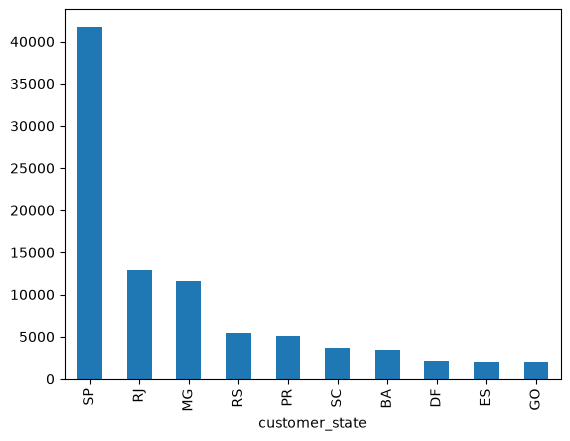

In [20]:
#Customer state distribution
df_customer['customer_state'].value_counts().head(10).plot(kind='bar')

In [21]:
df_customer['customer_city'].value_counts().head(10)

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: count, dtype: int64

<Axes: xlabel='customer_city'>

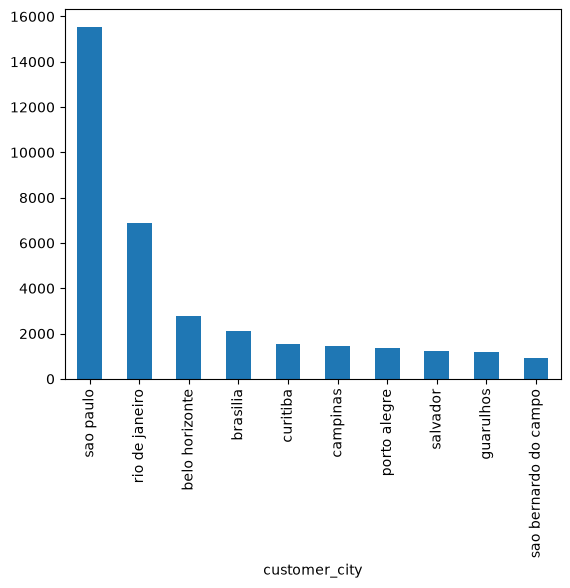

In [22]:
df_customer['customer_city'].value_counts().head(10).plot(kind='bar')

In [23]:
df_customer['customer_city'].nunique()

4119

In [24]:
df_customer['customer_city'].value_counts().head(10)

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: count, dtype: int64

In [25]:
df_customer.describe()

,customer_zip_code_prefix
count,99441.000000
mean,35137.474583
std,29797.938996
min,1003.000000
25%,11347.000000
50%,24416.000000
75%,58900.000000
max,99990.000000


<Axes: xlabel='customer_state'>

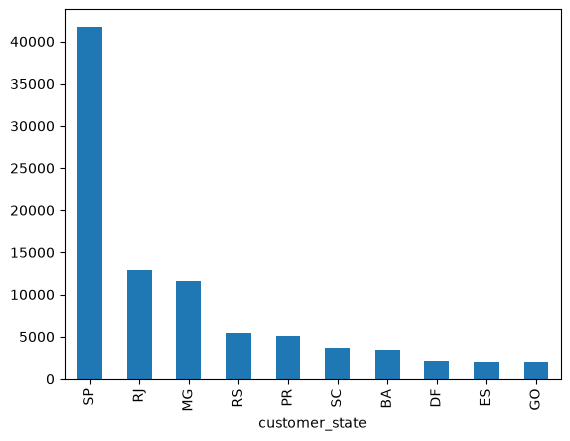

In [26]:
df_customer['customer_state'].value_counts().head(10).plot(kind='bar')

<Axes: title={'center': 'Top 10 States by Customer Count'}, xlabel='State', ylabel='Number of Customer'>

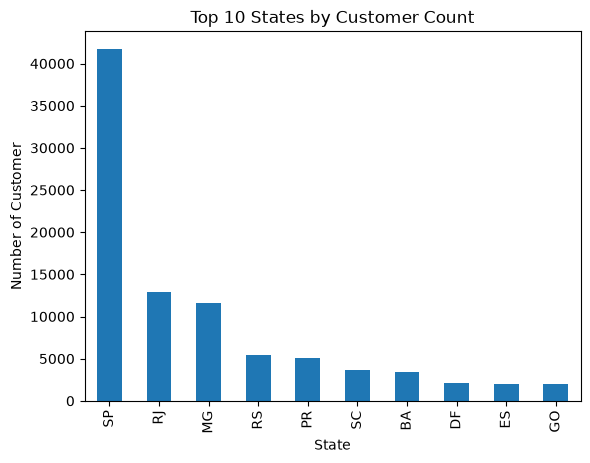

In [27]:
df_customer['customer_state'].value_counts().head(10).plot(
    kind='bar',
    title='Top 10 States by Customer Count',
    xlabel='State',
    ylabel='Number of Customer'
)

[Text(0, 0, '41746'),
 Text(0, 0, '12852'),
 Text(0, 0, '11635'),
 Text(0, 0, '5466'),
 Text(0, 0, '5045'),
 Text(0, 0, '3637'),
 Text(0, 0, '3380'),
 Text(0, 0, '2140'),
 Text(0, 0, '2033'),
 Text(0, 0, '2020')]

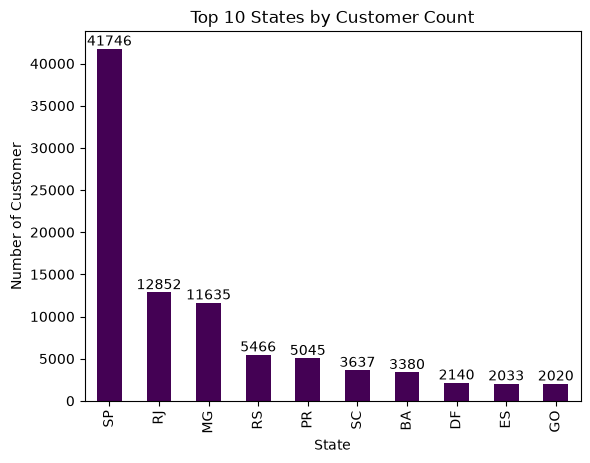

In [28]:
ax=df_customer['customer_state'].value_counts().head(10).plot(
    kind='bar',
    colormap='viridis',
    title='Top 10 States by Customer Count',
    xlabel='State',
    ylabel='Number of Customer'
)
ax.bar_label(ax.containers[0])

In [29]:
import os
files=os.listdir("Olist_Dataset")
for file in files:
    print(file)

.ipynb_checkpoints
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_master_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [30]:
df_orders=pd.read_csv(
    'Olist_Dataset/olist_orders_dataset.csv'
)

In [31]:
df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [32]:
df_orders.shape

(99441, 8)

In [33]:
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [34]:
pd.set_option('display.max_columns',None)
df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [35]:
df_orders.head().T

,0,1,2,3,4
order_id,e481f51cbdc54678b7cc49136f2d6af7,53cdb2fc8bc7dce0b6741e2150273451,47770eb9100c2d0c44946d9cf07ec65d,949d5b44dbf5de918fe9c16f97b45f8a,ad21c59c0840e6cb83a9ceb5573f8159
customer_id,9ef432eb6251297304e76186b10a928d,b0830fb4747a6c6d20dea0b8c802d7ef,41ce2a54c0b03bf3443c3d931a367089,f88197465ea7920adcdbec7375364d82,8ab97904e6daea8866dbdbc4fb7aad2c
order_status,delivered,delivered,delivered,delivered,delivered
order_purchase_timestamp,2017-10-02 10:56:33,2018-07-24 20:41:37,2018-08-08 08:38:49,2017-11-18 19:28:06,2018-02-13 21:18:39
order_approved_at,2017-10-02 11:07:15,2018-07-26 03:24:27,2018-08-08 08:55:23,2017-11-18 19:45:59,2018-02-13 22:20:29
order_delivered_carrier_date,2017-10-04 19:55:00,2018-07-26 14:31:00,2018-08-08 13:50:00,2017-11-22 13:39:59,2018-02-14 19:46:34
order_delivered_customer_date,2017-10-10 21:25:13,2018-08-07 15:27:45,2018-08-17 18:06:29,2017-12-02 00:28:42,2018-02-16 18:17:02
order_estimated_delivery_date,2017-10-18 00:00:00,2018-08-13 00:00:00,2018-09-04 00:00:00,2017-12-15 00:00:00,2018-02-26 00:00:00


In [36]:
df_orders.shape


(99441, 8)

In [37]:
df_orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [38]:
df_orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [39]:
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [40]:
(df_orders['order_status'].value_counts(normalize=True)*100).round(2)

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64

In [41]:
df_orders.duplicated().sum()

np.int64(0)

In [42]:
df_orders['order_status'].nunique()

8

In [43]:
df_orders['order_status'].unique()

<ArrowStringArray>
[  'delivered',    'invoiced',     'shipped',  'processing', 'unavailable',
    'canceled',     'created',    'approved']
Length: 8, dtype: str

In [44]:
df_orders['order_purchase_timestamp'].head()

0    2017-10-02 10:56:33
1    2018-07-24 20:41:37
2    2018-08-08 08:38:49
3    2017-11-18 19:28:06
4    2018-02-13 21:18:39
Name: order_purchase_timestamp, dtype: str

In [45]:
df_orders['order_purchase_timestamp'].dtype

<StringDtype(na_value=nan)>

In [46]:
df_orders['order_purchase_timestamp']=pd.to_datetime(
    df_orders['order_purchase_timestamp']
)

In [47]:
df_orders['order_purchase_timestamp'].dtype

dtype('<M8[us]')

In [48]:
df_orders['order_year']=df_orders['order_purchase_timestamp'].dt.year

In [49]:
df_orders['order_year'].value_counts().sort_index()

order_year
2016      329
2017    45101
2018    54011
Name: count, dtype: int64

In [50]:
df_orders['order-month']=df_orders['order_purchase_timestamp'].dt.month

In [51]:
df_orders['order-month'].value_counts().sort_index()

order-month
1      8069
2      8508
3      9893
4      9343
5     10573
6      9412
7     10318
8     10843
9      4305
10     4959
11     7544
12     5674
Name: count, dtype: int64

# Bar chart of monthly order

<Axes: title={'center': 'Month_wise Order count'}, xlabel='Month', ylabel='Number of Orders'>

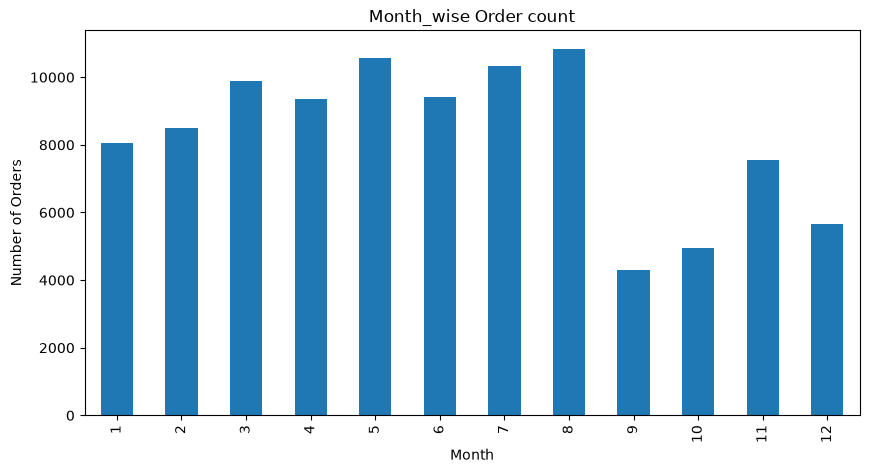

In [52]:
df_orders['order-month'].value_counts().sort_index().plot(
    kind='bar',
    title='Month_wise Order count',
    xlabel='Month',
    ylabel='Number of Orders',
    figsize=(10,5)
)

In [53]:
df_orders.groupby(['order_year','order-month']).size()

order_year  order-month
2016        9                 4
            10              324
            12                1
2017        1               800
            2              1780
            3              2682
            4              2404
            5              3700
            6              3245
            7              4026
            8              4331
            9              4285
            10             4631
            11             7544
            12             5673
2018        1              7269
            2              6728
            3              7211
            4              6939
            5              6873
            6              6167
            7              6292
            8              6512
            9                16
            10                4
dtype: int64

In [54]:
monthly_orders=df_orders.groupby(['order_year','order-month']).size().reset_index(name='total_orders')

In [55]:
monthly_orders.head(10)

,order_year,order-month,total_orders
0,2016,9,4
1,2016,10,324
2,2016,12,1
3,2017,1,800
4,2017,2,1780
5,2017,3,2682
6,2017,4,2404
7,2017,5,3700
8,2017,6,3245
9,2017,7,4026


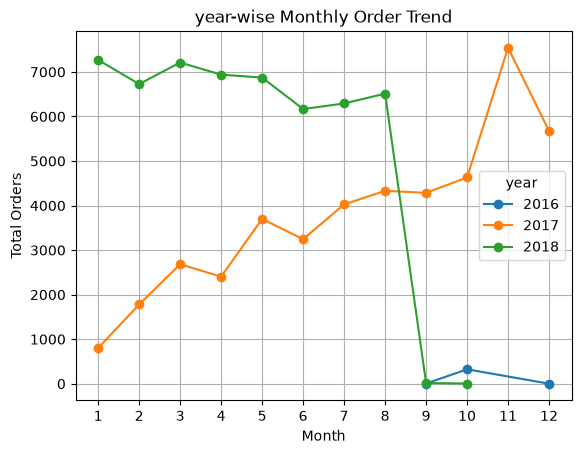

In [56]:
import matplotlib.pyplot as plt
for year in monthly_orders['order_year'].unique():
    year_data=monthly_orders[monthly_orders['order_year']==year]
    plt.plot(
        year_data['order-month'],
        year_data['total_orders'],
        marker='o',
        label=year
    )

plt.title('year-wise Monthly Order Trend')
plt.xlabel('Month')
plt.ylabel('Total Orders')
plt.xticks(range(1,13))
plt.legend(title='year')
plt.grid(True)
plt.show()

# Delivery Time Analysis

In [57]:
df_orders['order_delivered_customer_date']=pd.to_datetime(
    df_orders['order_delivered_customer_date'],
    errors='coerce'
)

In [58]:
df_orders['order_purchase_timestamp'] = pd.to_datetime(
    df_orders['order_purchase_timestamp'],
    errors='coerce'
)

df_orders['order_delivered_customer_date'] = pd.to_datetime(
    df_orders['order_delivered_customer_date'],
    errors='coerce'
)

In [59]:
df_orders[['order_purchase_timestamp',
           'order_delivered_customer_date']].dtypes

order_purchase_timestamp         datetime64[us]
order_delivered_customer_date    datetime64[us]
dtype: object

In [60]:
df_orders['delivery_days'] = (
    df_orders['order_delivered_customer_date'] -
    df_orders['order_purchase_timestamp']
).dt.days

In [61]:
df_orders[df_orders['order_status'] == 'delivered']['delivery_days'].describe()

count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64

# Delivery days

In [62]:
df_orders['delivery_days'] = (
    df_orders['order_delivered_customer_date'] -
    df_orders['order_purchase_timestamp']
).dt.days

In [63]:
df_orders[df_orders['order_status']=='delivered']['delivery_days'].describe()

count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64

# convert estimated delivery date into date and time

In [64]:
df_orders['order_estimated_delivery_date']=pd.to_datetime(
    df_orders['order_estimated_delivery_date'],
    errors='coerce'
)

# Delivery comparison column

In [65]:
df_orders['delivery_difference'] = (
    df_orders['order_delivered_customer_date'] -
    df_orders['order_estimated_delivery_date']
).dt.days

# delivered orders result check

In [66]:
df_orders[df_orders['order_status'] == 'delivered'][
    ['order_id', 'order_delivered_customer_date',
     'order_estimated_delivery_date', 'delivery_difference']
].head(10)

,order_id,order_delivered_customer_date,order_estimated_delivery_date,delivery_difference
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-10 21:25:13,2017-10-18,-8.0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-07 15:27:45,2018-08-13,-6.0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-17 18:06:29,2018-09-04,-18.0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-02 00:28:42,2017-12-15,-13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-16 18:17:02,2018-02-26,-10.0
5,a4591c265e18cb1dcee52889e2d8acc3,2017-07-26 10:57:55,2017-08-01,-6.0
7,6514b8ad8028c9f2cc2374ded245783f,2017-05-26 12:55:51,2017-06-07,-12.0
8,76c6e866289321a7c93b82b54852dc33,2017-02-02 14:08:10,2017-03-06,-32.0
9,e69bfb5eb88e0ed6a785585b27e16dbf,2017-08-16 17:14:30,2017-08-23,-7.0
10,e6ce16cb79ec1d90b1da9085a6118aeb,2017-05-29 11:18:31,2017-06-07,-9.0


# On-time aur Late orders count

In [67]:
delivered_orders = df_orders[
    df_orders['order_status'] == 'delivered'
].copy()

In [68]:
delivered_orders['delivery_status'] = np.select(
    [
        delivered_orders['delivery_difference'] < 0,
        delivered_orders['delivery_difference'] == 0,
        delivered_orders['delivery_difference'] > 0
    ],
    ['Early', 'On Time', 'Late'],
    default='Unknown'
)

In [69]:
delivered_orders['delivery_status'].value_counts()

delivery_status
Early      88644
Late        6534
On Time     1292
Unknown        8
Name: count, dtype: int64

# delivery status percentage.

In [70]:
(delivered_orders['delivery_status'].value_counts(normalize=True) * 100).round(2)

delivery_status
Early      91.88
Late        6.77
On Time     1.34
Unknown     0.01
Name: proportion, dtype: float64

# bar chart to visualize delivery status.

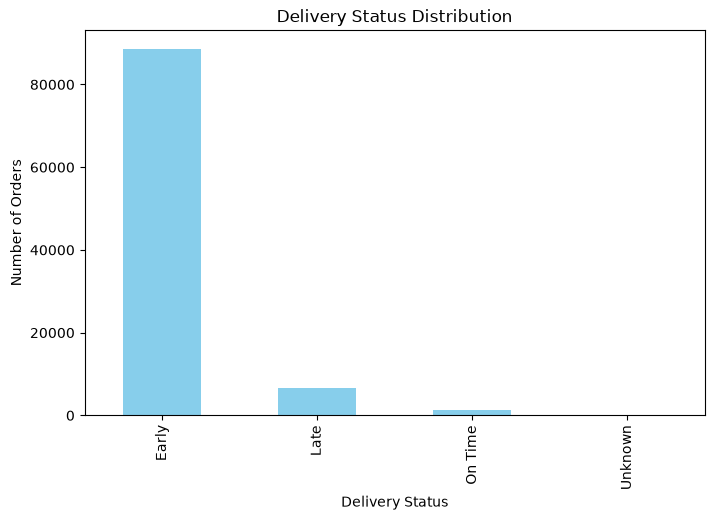

In [71]:
delivered_orders['delivery_status'].value_counts().plot(
    kind='bar',
    title='Delivery Status Distribution',
    xlabel='Delivery Status',
    ylabel='Number of Orders',
    color='skyblue',
    figsize=(8, 5)
)

plt.show()

# Payments Analysis
## Payment CSV load

In [72]:
df_payments = pd.read_csv('Olist_Dataset/olist_order_payments_dataset.csv')

In [73]:
df_payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [74]:
df_payments.shape

(103886, 5)

In [75]:
df_payments.info()

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 8.1 MB


In [76]:
df_payments.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [77]:
df_payments.duplicated().sum()

np.int64(0)

In [78]:
df_payments['payment_type'].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

## Calculate payment method percentages.

In [79]:
(df_payments['payment_type'].value_counts(normalize=True) * 100).round(2)

payment_type
credit_card    73.92
boleto         19.04
voucher         5.56
debit_card      1.47
not_defined     0.00
Name: proportion, dtype: float64

In [80]:
df_payments['payment_value'].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

## Calculate total revenue collected through payments.

In [81]:
df_payments['payment_value'].sum()

np.float64(16008872.120000001)

In [82]:
df_payments['payment_installments'].value_counts().sort_index()

payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

In [83]:
df_payments.groupby('payment_type')['payment_value'].sum().sort_values(ascending=False)

payment_type
credit_card    12542084.19
boleto          2869361.27
voucher          379436.87
debit_card       217989.79
not_defined           0.00
Name: payment_value, dtype: float64

## bar chart for payment value by payment type.

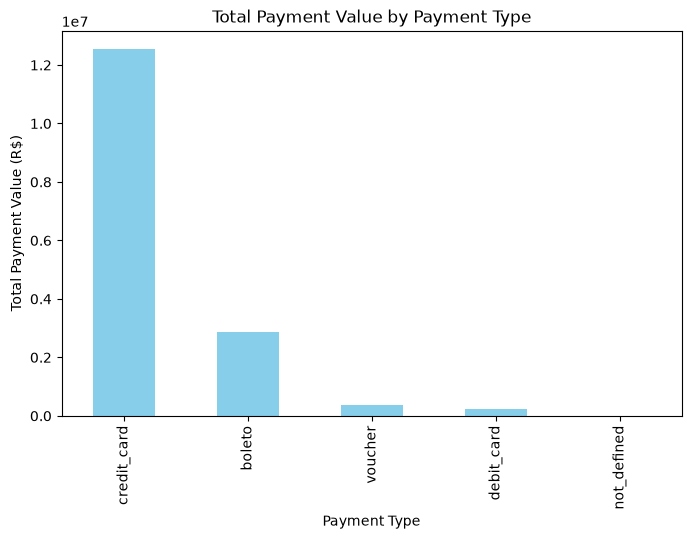

In [84]:
df_payments.groupby('payment_type')['payment_value'].sum().sort_values(
    ascending=False
).plot(
    kind='bar',
    title='Total Payment Value by Payment Type',
    xlabel='Payment Type',
    ylabel='Total Payment Value (R$)',
    color='skyblue',
    figsize=(8, 5)
)

plt.show()

## Payment Value by Installments

In [85]:
df_payments.groupby('payment_installments')['payment_value'].sum().sort_values(ascending=False)

payment_installments
1     5907233.36
10    2211577.34
2     1579283.03
3     1491103.80
8     1313423.34
4     1163907.61
5      961174.30
6      822611.81
7      305157.39
9      131015.92
12      42783.24
15      32970.93
18      13135.05
24      10980.88
20      10468.63
11       2873.44
14       2519.44
13       2407.40
16       1463.47
17       1396.82
21        731.10
23        236.48
22        228.71
0         188.63
Name: payment_value, dtype: float64

## Create a bar chart.

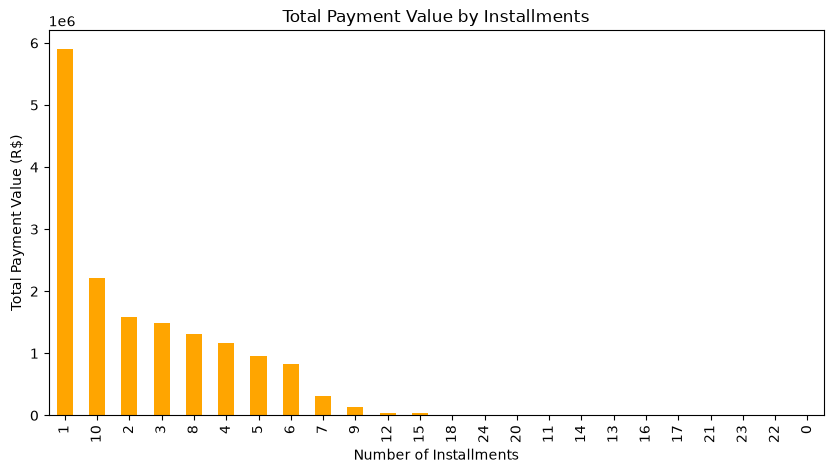

In [86]:
df_payments.groupby('payment_installments')['payment_value'].sum().sort_values(
    ascending=False
).plot(
    kind='bar',
    title='Total Payment Value by Installments',
    xlabel='Number of Installments',
    ylabel='Total Payment Value (R$)',
    figsize=(10, 5),
    color='orange'
)

plt.show()

# Order Items Analysis
## Load the order items CSV.


In [87]:
df_items = pd.read_csv('Olist_Dataset/olist_order_items_dataset.csv')

In [88]:
df_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [89]:
df_items.shape

(112650, 7)

In [90]:
df_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


## Check missing values and duplicates.

In [91]:
df_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [92]:
df_items.duplicated().sum()

np.int64(0)

## Calculate Total Sales (Revenue)



In [93]:
df_items['price'].sum()

np.float64(13591643.7)

## Total Freight Cost.

In [94]:
df_items['freight_value'].sum()

np.float64(2251909.54)

## Calculate Average Product Price.

In [95]:
df_items['price'].mean()

np.float64(120.65373901464713)

## Top 10 most expensive products by order item price.

In [96]:
df_items.nlargest(10, 'price')[['product_id', 'price']]

,product_id,price
3556,489ae2aa008f021502940f251d4cce7f,6735.00
112233,69c590f7ffc7bf8db97190b6cb6ed62e,6729.00
107841,1bdf5e6731585cf01aa8169c7028d6ad,6499.00
74336,a6492cc69376c469ab6f61d8f44de961,4799.00
11249,c3ed642d592594bb648ff4a04cee2747,4690.00
62086,259037a6a41845e455183f89c5035f18,4590.00
29193,a1beef8f3992dbd4cd8726796aa69c53,4399.87
45843,6cdf8fc1d741c76586d8b6b15e9eef30,4099.99
78310,dd113cb02b2af9c8e5787e8f1f0722f6,4059.00
59137,6902c1962dd19d540807d0ab8fade5c6,3999.90


## Top 10 products by total quantity sold.

In [97]:
df_items['product_id'].value_counts().head(10)

product_id
aca2eb7d00ea1a7b8ebd4e68314663af    527
99a4788cb24856965c36a24e339b6058    488
422879e10f46682990de24d770e7f83d    484
389d119b48cf3043d311335e499d9c6b    392
368c6c730842d78016ad823897a372db    388
53759a2ecddad2bb87a079a1f1519f73    373
d1c427060a0f73f6b889a5c7c61f2ac4    343
53b36df67ebb7c41585e8d54d6772e08    323
154e7e31ebfa092203795c972e5804a6    281
3dd2a17168ec895c781a9191c1e95ad7    274
Name: count, dtype: int64

## Top 10 sellers by number of items sold.

In [98]:
df_items['seller_id'].value_counts().head(10)

seller_id
6560211a19b47992c3666cc44a7e94c0    2033
4a3ca9315b744ce9f8e9374361493884    1987
1f50f920176fa81dab994f9023523100    1931
cc419e0650a3c5ba77189a1882b7556a    1775
da8622b14eb17ae2831f4ac5b9dab84a    1551
955fee9216a65b617aa5c0531780ce60    1499
1025f0e2d44d7041d6cf58b6550e0bfa    1428
7c67e1448b00f6e969d365cea6b010ab    1364
ea8482cd71df3c1969d7b9473ff13abc    1203
7a67c85e85bb2ce8582c35f2203ad736    1171
Name: count, dtype: int64

## Total Revenue by Seller (Top 10).

In [99]:
df_items.groupby('seller_id')['price'].sum().sort_values(
    ascending=False
).head(10)

seller_id
4869f7a5dfa277a7dca6462dcf3b52b2    229472.63
53243585a1d6dc2643021fd1853d8905    222776.05
4a3ca9315b744ce9f8e9374361493884    200472.92
fa1c13f2614d7b5c4749cbc52fecda94    194042.03
7c67e1448b00f6e969d365cea6b010ab    187923.89
7e93a43ef30c4f03f38b393420bc753a    176431.87
da8622b14eb17ae2831f4ac5b9dab84a    160236.57
7a67c85e85bb2ce8582c35f2203ad736    141745.53
1025f0e2d44d7041d6cf58b6550e0bfa    138968.55
955fee9216a65b617aa5c0531780ce60    135171.70
Name: price, dtype: float64

## average product price and freight value by seller.

In [100]:
df_items.groupby('seller_id')[['price', 'freight_value']].mean().sort_values(
    by='price', ascending=False
).head(10)

,price,freight_value
seller_id,,
80ceebb4ee9b31afb6c6a916a574a1e2,6729.000000,193.210000
ee27a8f15b1dded4d213a468ba4eb391,6499.000000,227.660000
585175ec331ea177fa47199e39a6170a,3549.000000,53.470000
abe021b01ba992245271b9aa422032df,3360.000000,58.620000
a00824eb9093d40e589b940ec45c4eb0,3133.323333,126.496667
e2a1ac9bf33e5549a2a4f834e70df2f8,2999.890000,40.222000
e908c0f3646e8b60375734a350d95d71,2951.000000,58.530000
d63c73efd41eb002280e7ec831424edb,2799.000000,84.295000
1444c08e64d55fb3c25f0f09c07ffcf2,2749.000000,69.740000


## average freight cost.

In [101]:
df_items['freight_value'].mean()

np.float64(19.990319928983578)

## Total Order Items per Order.

In [102]:
df_items.groupby('order_id')['order_item_id'].count().value_counts().sort_index()

order_item_id
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

## : Calculate average order value (AOV) using the Order Items dataset.

In [103]:
order_revenue = df_items.groupby('order_id')['price'].sum()

order_revenue.mean()

np.float64(137.75407637889444)

## Calculate total revenue by product

In [104]:
df_items.groupby('product_id')['price'].sum().sort_values(
    ascending=False
).head(10)

product_id
bb50f2e236e5eea0100680137654686c    63885.00
6cdd53843498f92890544667809f1595    54730.20
d6160fb7873f184099d9bc95e30376af    48899.34
d1c427060a0f73f6b889a5c7c61f2ac4    47214.51
99a4788cb24856965c36a24e339b6058    43025.56
3dd2a17168ec895c781a9191c1e95ad7    41082.60
25c38557cf793876c5abdd5931f922db    38907.32
5f504b3a1c75b73d6151be81eb05bdc9    37733.90
53b36df67ebb7c41585e8d54d6772e08    37683.42
aca2eb7d00ea1a7b8ebd4e68314663af    37608.90
Name: price, dtype: float64

## Calculate total orders and unique products.

In [105]:

print("Total Order Items:", len(df_items))
print("Unique Orders:", df_items['order_id'].nunique())
print("Unique Products:", df_items['product_id'].nunique())
print("Unique Sellers:", df_items['seller_id'].nunique())

Total Order Items: 112650
Unique Orders: 98666
Unique Products: 32951
Unique Sellers: 3095


## meerge order  item with orders 

In [106]:
df_sales = df_items.merge(
    df_orders[['order_id', 'order_purchase_timestamp']],
    on='order_id',
    how='left'
)

In [107]:
df_sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51


## Monthly Revenue Analysis

In [108]:
df_sales['order_purchase_timestamp'] = pd.to_datetime(
    df_sales['order_purchase_timestamp']
)

df_sales['order_month'] = df_sales['order_purchase_timestamp'].dt.to_period('M')

monthly_sales = df_sales.groupby('order_month')['price'].sum()

monthly_sales

order_month
2016-09        267.36
2016-10      49507.66
2016-12         10.90
2017-01     120312.87
2017-02     247303.02
2017-03     374344.30
2017-04     359927.23
2017-05     506071.14
2017-06     433038.60
2017-07     498031.48
2017-08     573971.68
2017-09     624401.69
2017-10     664219.43
2017-11    1010271.37
2017-12     743914.17
2018-01     950030.36
2018-02     844178.71
2018-03     983213.44
2018-04     996647.75
2018-05     996517.68
2018-06     865124.31
2018-07     895507.22
2018-08     854686.33
2018-09        145.00
Freq: M, Name: price, dtype: float64

## Monthly Sales Trend Chart.

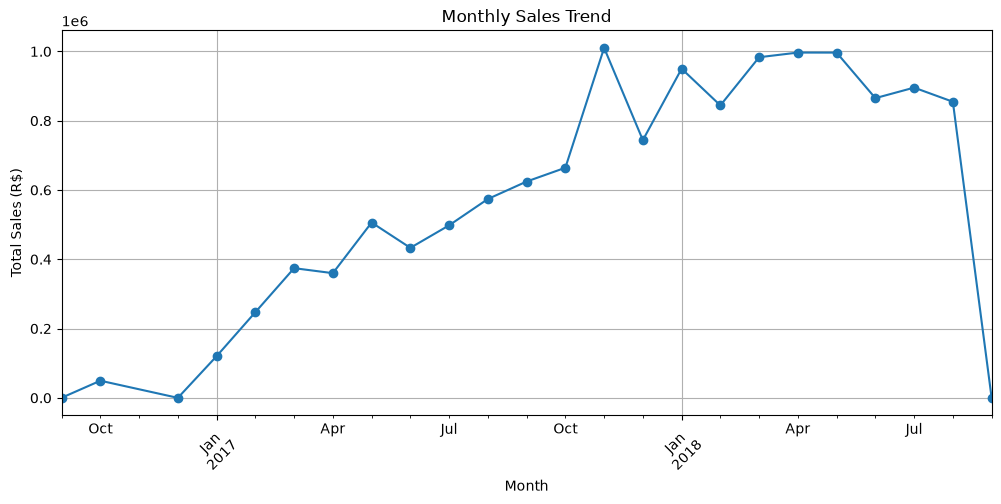

In [109]:
monthly_sales.plot(
    kind='line',
    marker='o',
    title='Monthly Sales Trend',
    xlabel='Month',
    ylabel='Total Sales (R$)',
    figsize=(12, 5)
)

plt.xticks(rotation=45)
plt.grid(True)
plt.show()

##  product price badhne par freight (delivery charge) bhi badhta hai ya nahi.

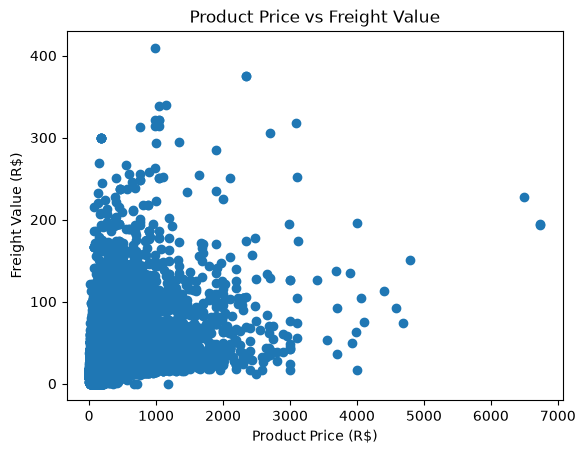

In [110]:
plt.scatter(df_items['price'], df_items['freight_value'])

plt.title('Product Price vs Freight Value')
plt.xlabel('Product Price (R$)')
plt.ylabel('Freight Value (R$)')
plt.show()

# Products.

In [111]:
df_products = pd.read_csv(
    'Olist_Dataset/olist_products_dataset.csv'
)

df_products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [112]:
df_products.shape


(32951, 9)

In [113]:
df_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 3.7 MB


In [114]:
df_products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [115]:
df_products.duplicated().sum()

np.int64(0)

# unique product categories.

In [116]:
df_products['product_category_name'].nunique()

73

In [117]:
df_products['product_category_name'].value_counts().head(10)

product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64

##  Top 10 categories ka bar chart

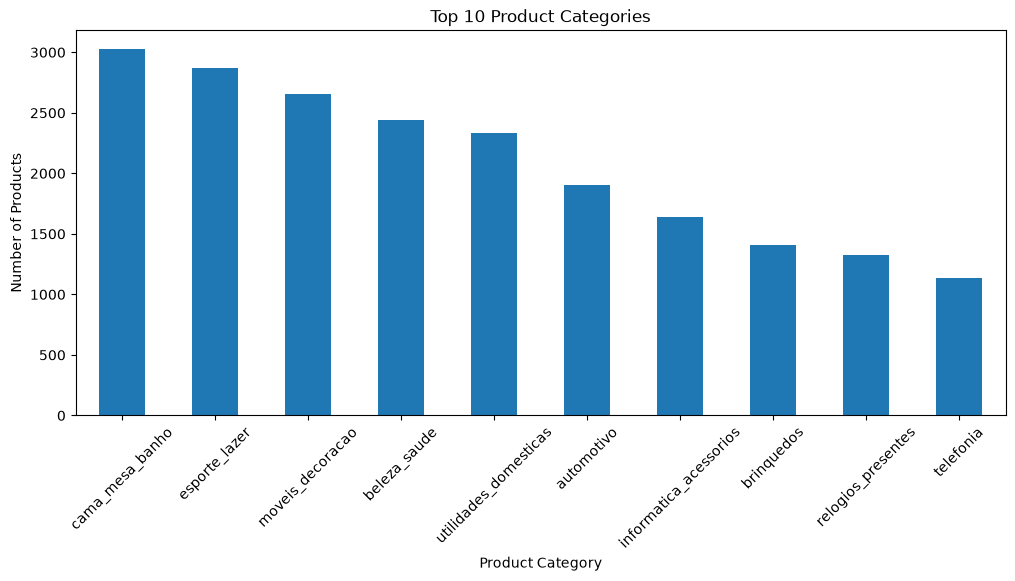

In [118]:
df_products['product_category_name'].value_counts().head(10).plot(
    kind='bar',
    figsize=(12,5),
    title='Top 10 Product Categories'
)

plt.xlabel('Product Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=45)
plt.show()

## Product Weight Analysis

In [119]:
df_products['product_weight_g'].describe()

count    32949.000000
mean      2276.472488
std       4282.038731
min          0.000000
25%        300.000000
50%        700.000000
75%       1900.000000
max      40425.000000
Name: product_weight_g, dtype: float64

## product weight  distribution visualize

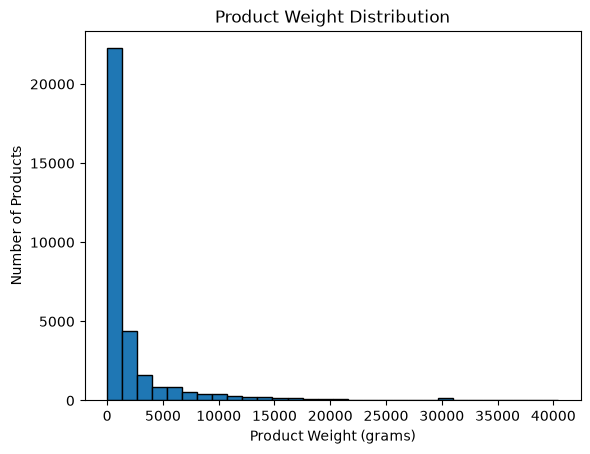

In [120]:
plt.hist(df_products['product_weight_g'], bins=30, edgecolor='black')

plt.title('Product Weight Distribution')
plt.xlabel('Product Weight (grams)')
plt.ylabel('Number of Products')
plt.show()

## Product Dimensions Analysis k

In [121]:
df_products['product_volume_cm3'] = (
    df_products['product_length_cm'] *
    df_products['product_height_cm'] *
    df_products['product_width_cm']
)

df_products['product_volume_cm3'].describe()

count     32949.000000
mean      16564.096695
std       27057.041650
min         168.000000
25%        2880.000000
50%        6840.000000
75%       18480.000000
max      296208.000000
Name: product_volume_cm3, dtype: float64

## : Product Photos Quantity.

In [122]:
df_products['product_photos_qty'].value_counts().sort_index()

product_photos_qty
1.0     16489
2.0      6263
3.0      3860
4.0      2428
5.0      1484
6.0       968
7.0       343
8.0       192
9.0       105
10.0       95
11.0       46
12.0       35
13.0        9
14.0        5
15.0        8
17.0        7
18.0        2
19.0        1
20.0        1
Name: count, dtype: int64

## bar chart

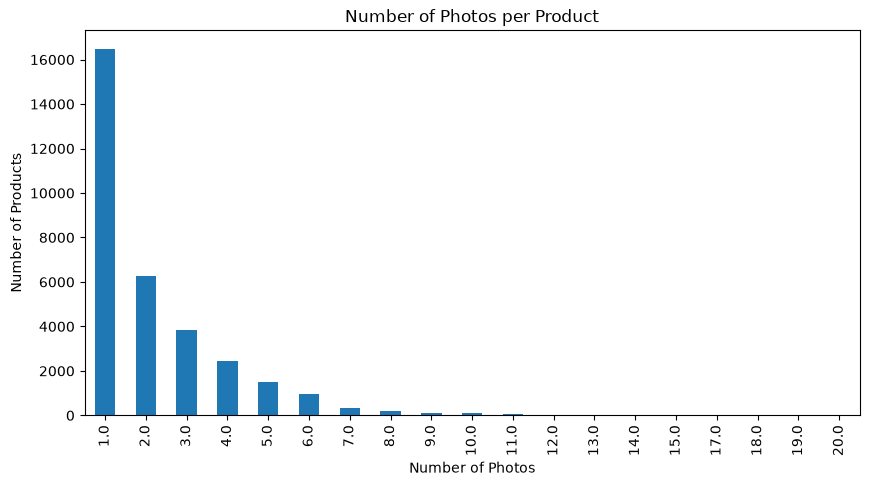

In [123]:
df_products['product_photos_qty'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(10, 5),
    title='Number of Photos per Product'
)

plt.xlabel('Number of Photos')
plt.ylabel('Number of Products')
plt.show()

In [124]:
df_products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
product_volume_cm3              2
dtype: int64

## whether the same 610 products have missing values

In [125]:
df_products[
    df_products['product_category_name'].isnull()
].head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_volume_cm3
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0,2856.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0,2240.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0,8000.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0,50430.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0,2940.0


## 2 missing physical records inspect

In [126]:
df_products[
    df_products['product_weight_g'].isnull()
]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_volume_cm3
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Missing values percentage

In [127]:
(df_products.isnull().mean() * 100).round(2)

product_id                    0.00
product_category_name         1.85
product_name_lenght           1.85
product_description_lenght    1.85
product_photos_qty            1.85
product_weight_g              0.01
product_length_cm             0.01
product_height_cm             0.01
product_width_cm              0.01
product_volume_cm3            0.01
dtype: float64

## Check category-wise missing information

In [128]:
df_products[
    df_products['product_category_name'].isnull()
].shape

(610, 10)

##  Product Category Name Translation Analysis


In [129]:
df_translation = pd.read_csv(
    'Olist_Dataset/product_category_name_translation.csv'
)

df_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


## Check missing categories in the original products dataset

In [130]:
df_products['product_category_name'].isnull().sum()

np.int64(610)

## Merge Products and Translation datasets

In [131]:
df_products = df_products.merge(
    df_translation,
    on='product_category_name',
    how='left'
)

In [132]:
df_products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_volume_cm3,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,2240.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,10800.0,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,2430.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,2704.0,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,4420.0,housewares


### Verify the merge

In [133]:
df_products.shape

(32951, 11)

In [134]:
df_products['product_category_name_english'].isnull().sum()

np.int64(623)

## Find untranslated categories

In [135]:
df_products[
    df_products['product_category_name_english'].isnull() &
    df_products['product_category_name'].notnull()
]['product_category_name'].unique()

<ArrowStringArray>
['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Length: 2, dtype: str

## Check how many products belong to these categories

In [136]:
df_products[
    df_products['product_category_name'].isin(
        ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
    )
]['product_category_name'].value_counts()

product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3
Name: count, dtype: int64

## Handle these 2 untranslated categories

In [137]:
df_products['product_category_name_english'] = (
    df_products['product_category_name_english'].fillna(
        df_products['product_category_name'].map({
            'pc_gamer': 'pc_gamer',
            'portateis_cozinha_e_preparadores_de_alimentos': 'small_appliances'
        })
    )
)

In [138]:
df_products['product_category_name_english'].isnull().sum()

np.int64(610)

## Verify both translated categories

In [139]:
df_products[
    df_products['product_category_name'].isin(
        ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
    )
][['product_category_name', 'product_category_name_english']]

,product_category_name,product_category_name_english
1628,pc_gamer,pc_gamer
5821,portateis_cozinha_e_preparadores_de_alimentos,small_appliances
7325,portateis_cozinha_e_preparadores_de_alimentos,small_appliances
7478,pc_gamer,pc_gamer
8819,portateis_cozinha_e_preparadores_de_alimentos,small_appliances
11039,portateis_cozinha_e_preparadores_de_alimentos,small_appliances
14266,portateis_cozinha_e_preparadores_de_alimentos,small_appliances
16182,portateis_cozinha_e_preparadores_de_alimentos,small_appliances
16930,pc_gamer,pc_gamer
17800,portateis_cozinha_e_preparadores_de_alimentos,small_appliances


## Check numerical columns for outliers

In [140]:
df_products.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_volume_cm3
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728,16564.096695
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047,27057.041650
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000,168.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000,2880.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000,6840.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000,18480.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000,296208.000000


## Check zero-weight products

In [141]:
df_products[df_products['product_weight_g'] == 0]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_volume_cm3,product_category_name_english
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.0,529.0,1.0,0.0,30.0,25.0,30.0,22500.0,bed_bath_table
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.0,528.0,1.0,0.0,30.0,25.0,30.0,22500.0,bed_bath_table
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0,22500.0,bed_bath_table
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0,22500.0,bed_bath_table


## Check zero values in all numerical columns

In [142]:
(df_products.select_dtypes(include='number') == 0).sum()

product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              4
product_length_cm             0
product_height_cm             0
product_width_cm              0
product_volume_cm3            0
dtype: int64

In [143]:
df_products[
    df_products['product_category_name_english'] == 'bed_bath_table'
]['product_weight_g'].describe()

count     3029.000000
mean      2456.405084
std       3732.667484
min          0.000000
25%        700.000000
50%       1250.000000
75%       2300.000000
max      40425.000000
Name: product_weight_g, dtype: float64

## Calculate median excluding zero weights

In [144]:
df_products[
    (df_products['product_category_name_english'] == 'bed_bath_table') &
    (df_products['product_weight_g'] > 0)
]['product_weight_g'].median()

np.float64(1250.0)

## Create a cleaned weight column

In [145]:
df_products['product_weight_cleaned'] = df_products['product_weight_g'].replace(0, 1250)

In [146]:
(df_products['product_weight_cleaned'] == 0).sum()

np.int64(0)

## Check missing values in physical dimensions

In [147]:
df_products[
    df_products['product_length_cm'].isnull()
]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_volume_cm3,product_category_name_english,product_weight_cleaned
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN,NaN,baby,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Baby category ke dimensions ka median

In [148]:
df_products[
    df_products['product_category_name_english'] == 'baby'
][['product_length_cm', 'product_height_cm', 'product_width_cm']].median()

product_length_cm    33.0
product_height_cm    16.0
product_width_cm     25.0
dtype: float64

In [149]:
df_products['product_length_cleaned'] = df_products['product_length_cm']
df_products['product_height_cleaned'] = df_products['product_height_cm']
df_products['product_width_cleaned'] = df_products['product_width_cm']

### Handling Missing Product Dimensions (Category-wise Median Imputation)

In [150]:
baby_mask = df_products['product_category_name_english'] == 'baby'

df_products.loc[baby_mask, 'product_length_cleaned'] = (
    df_products.loc[baby_mask, 'product_length_cleaned'].fillna(33.0)
)

df_products.loc[baby_mask, 'product_height_cleaned'] = (
    df_products.loc[baby_mask, 'product_height_cleaned'].fillna(16.0)
)

df_products.loc[baby_mask, 'product_width_cleaned'] = (
    df_products.loc[baby_mask, 'product_width_cleaned'].fillna(25.0)
)

In [151]:
df_products.loc[
    8578,
    ['product_length_cleaned', 'product_height_cleaned', 'product_width_cleaned']
]

product_length_cleaned    33.0
product_height_cleaned    16.0
product_width_cleaned     25.0
Name: 8578, dtype: float64

In [152]:
df_products[
    ['product_length_cleaned', 'product_height_cleaned', 'product_width_cleaned']
].isnull().sum()

product_length_cleaned    1
product_height_cleaned    1
product_width_cleaned     1
dtype: int64

In [153]:
(df_products[
    ['product_length_cleaned', 'product_height_cleaned', 'product_width_cleaned']
] == 0).sum()

product_length_cleaned    0
product_height_cleaned    0
product_width_cleaned     0
dtype: int64

### Missing product weight handle

In [154]:
df_products['product_weight_cleaned'].isnull().sum()

np.int64(2)

## Baby category ka median weight

In [155]:
df_products[
    (df_products['product_category_name_english'] == 'baby') &
    (df_products['product_weight_cleaned'] > 0)
]['product_weight_cleaned'].median()

np.float64(850.0)

### Cleaned weight  missing value fill

In [156]:
baby_mask = df_products['product_category_name_english'] == 'baby'

df_products.loc[baby_mask, 'product_weight_cleaned'] = (
    df_products.loc[baby_mask, 'product_weight_cleaned'].fillna(850.0)
)

In [157]:
df_products.loc[
    8578,
    ['product_weight_g', 'product_weight_cleaned']
]

product_weight_g            NaN
product_weight_cleaned    850.0
Name: 8578, dtype: float64

### Final missing-value check

In [158]:
df_products[
    ['product_weight_cleaned',
     'product_length_cleaned',
     'product_height_cleaned',
     'product_width_cleaned']
].isnull().sum()

product_weight_cleaned    1
product_length_cleaned    1
product_height_cleaned    1
product_width_cleaned     1
dtype: int64

### Product Dataset Cleaning Summary

#### - Checked and handled missing values.
#### - Translated Portuguese product categories into English.
#### - Manually mapped 2 untranslated categories.
#### - Replaced 4 zero product weights using category median.
#### - Filled missing dimensions for 1 baby-category product using category medians.
#### - Filled 1 missing product weight using baby-category median.
#### - Retained 1 product with unknown category and missing physical attributes rather than guessing values.

In [159]:
print("Final Shape:", df_products.shape)
print("Duplicate Rows:", df_products.duplicated().sum())
print("Total Products:", df_products['product_id'].nunique())

Final Shape: (32951, 15)
Duplicate Rows: 0
Total Products: 32951


# Sellers Dataset

In [160]:
df_sellers = pd.read_csv(
    'Olist_Dataset/olist_sellers_dataset.csv'
)

In [161]:
df_sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [162]:
df_sellers.shape

(3095, 4)

In [163]:
df_sellers.info()

<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 230.3 KB


In [164]:
df_sellers.isnull().sum()

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [165]:
df_sellers.duplicated().sum()

np.int64(0)

In [166]:
df_sellers['seller_id'].nunique()

3095

### state-wise seller count

In [167]:
df_sellers['seller_state'].value_counts()

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
CE      13
PE       9
PB       6
RN       5
MS       5
MT       4
RO       2
SE       2
AC       1
PI       1
MA       1
AM       1
PA       1
Name: count, dtype: int64

### City-wise seller analysis

In [168]:
df_sellers['seller_city'].nunique()

611

In [169]:
df_sellers['seller_city'].value_counts().head(10)

seller_city
sao paulo         694
curitiba          127
rio de janeiro     96
belo horizonte     68
ribeirao preto     52
guarulhos          50
ibitinga           49
santo andre        45
campinas           41
maringa            40
Name: count, dtype: int64

### Top 10 Seller Cities Visualization

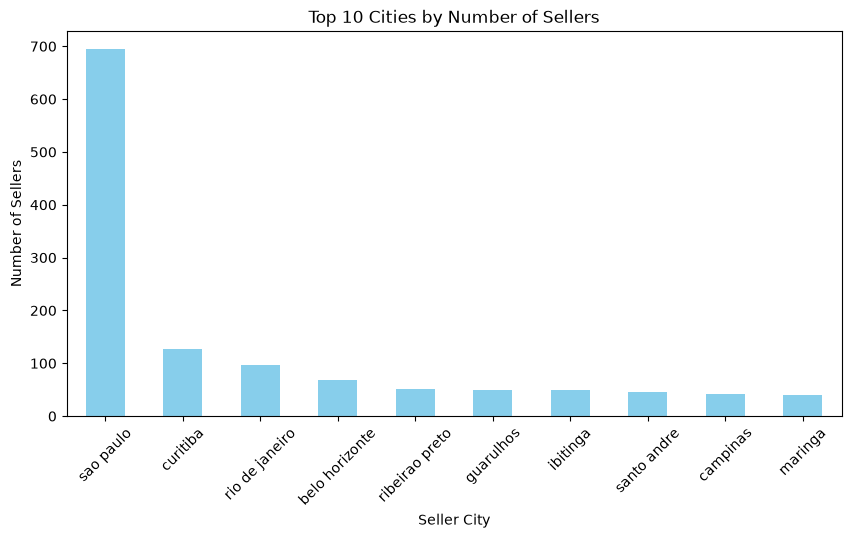

In [170]:
top_cities = df_sellers['seller_city'].value_counts().head(10)

top_cities.plot(
    kind='bar',
    title='Top 10 Cities by Number of Sellers',
    xlabel='Seller City',
    ylabel='Number of Sellers',
    figsize=(10,5),
    color='skyblue'
)

plt.xticks(rotation=45)
plt.show()

### State-wise Seller Visualization

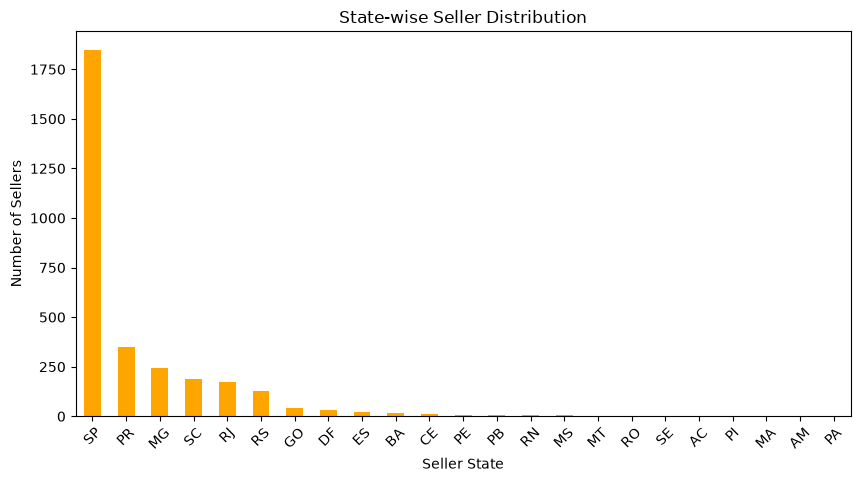

In [171]:
top_states = df_sellers['seller_state'].value_counts()

top_states.plot(
    kind='bar',
    title='State-wise Seller Distribution',
    xlabel='Seller State',
    ylabel='Number of Sellers',
    figsize=(10,5),
    color='orange'
)

plt.xticks(rotation=45)
plt.show()

###  Seller Dataset Final Validation

In [172]:
print("Total Sellers:", df_sellers.shape[0])
print("Unique Seller IDs:", df_sellers['seller_id'].nunique())
print("Unique Cities:", df_sellers['seller_city'].nunique())
print("Unique States:", df_sellers['seller_state'].nunique())
print("Duplicate Rows:", df_sellers.duplicated().sum())

Total Sellers: 3095
Unique Seller IDs: 3095
Unique Cities: 611
Unique States: 23
Duplicate Rows: 0


# Reviews Dataset

In [173]:
df_reviews = pd.read_csv(
    'Olist_Dataset/olist_order_reviews_dataset.csv'
)

In [174]:
df_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


# Dataset structure check

In [175]:
df_reviews.shape

(99224, 7)

In [176]:
df_reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB


In [177]:
df_reviews.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [178]:
df_reviews.duplicated().sum()

np.int64(0)

### Review Score Analysis

In [179]:
df_reviews['review_score'].unique()

array([4, 5, 1, 3, 2])

In [180]:
df_reviews['review_score'].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

### Rating Percentage

In [181]:
(df_reviews['review_score'].value_counts(normalize=True).sort_index() * 100).round(2)

review_score
1    11.51
2     3.18
3     8.24
4    19.29
5    57.78
Name: proportion, dtype: float64

### Review Score Visualization

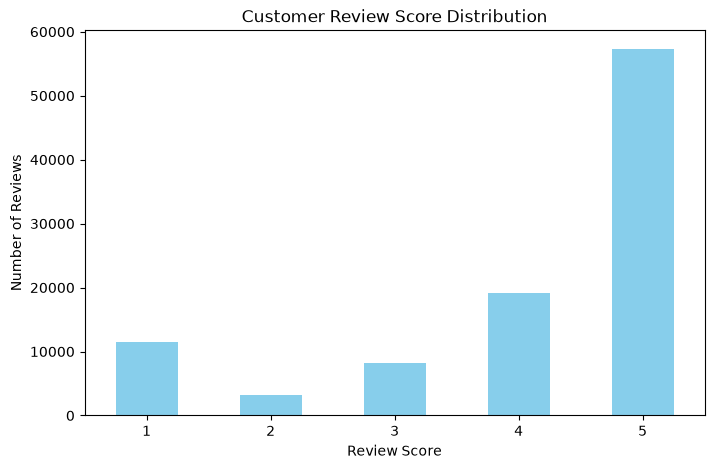

In [182]:
review_counts = df_reviews['review_score'].value_counts().sort_index()

review_counts.plot(
    kind='bar',
    title='Customer Review Score Distribution',
    xlabel='Review Score',
    ylabel='Number of Reviews',
    figsize=(8,5),
    color='skyblue'
)

plt.xticks(rotation=0)
plt.show()

### Average Customer Rating

In [183]:
df_reviews['review_score'].mean()

np.float64(4.08642062404257)

### Positive vs Negative Reviews

In [184]:

df_reviews['review_category'] = np.select(
    [
        df_reviews['review_score'] >= 4,
        df_reviews['review_score'] == 3,
        df_reviews['review_score'] <= 2
    ],
    ['Positive', 'Neutral', 'Negative'],
    default='Unknown'
)

In [185]:
df_reviews['review_category'].value_counts()

review_category
Positive    76470
Negative    14575
Neutral      8179
Name: count, dtype: int64

### Category-wise Percentage

In [186]:
(df_reviews['review_category'].value_counts(normalize=True) * 100).round(2)

review_category
Positive    77.07
Negative    14.69
Neutral      8.24
Name: proportion, dtype: float64

### Written Review Analysis

In [187]:
df_reviews['review_comment_message'].notnull().sum()

np.int64(40977)

In [188]:
df_reviews['review_comment_message'].isnull().sum()

np.int64(58247)

#### Review Comment Length Analysis

In [189]:
df_reviews['comment_length'] = df_reviews['review_comment_message'].str.len()

In [190]:
df_reviews['comment_length'].mean()

np.float64(68.63767479317666)

### Short, Medium and Long Reviews

In [191]:
df_reviews['comment_type'] = np.select(
    [
        df_reviews['comment_length'] <= 50,
        (df_reviews['comment_length'] > 50) & (df_reviews['comment_length'] <= 150),
        df_reviews['comment_length'] > 150
    ],
    ['Short', 'Medium', 'Long'],
    default='No Comment'
)

In [192]:

df_reviews['comment_type'].value_counts()

comment_type
No Comment    58247
Short         19624
Medium        16667
Long           4686
Name: count, dtype: int64

### Comment Type Visualization

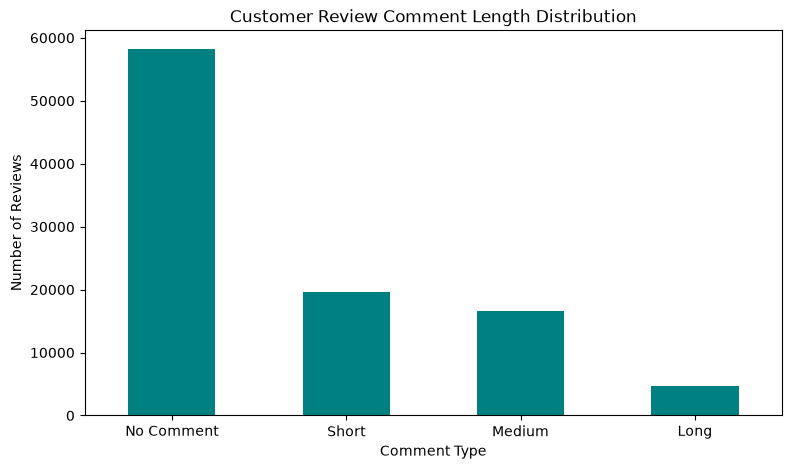

In [193]:
df_reviews['comment_type'].value_counts().plot(
    kind='bar',
    title='Customer Review Comment Length Distribution',
    xlabel='Comment Type',
    ylabel='Number of Reviews',
    figsize=(9,5),
    color='teal'
)

plt.xticks(rotation=0)
plt.show()

## Review Date Analysis

In [194]:
df_reviews['review_creation_date'] = pd.to_datetime(
    df_reviews['review_creation_date'],
    errors='coerce'
)

In [195]:
df_reviews['review_year'] = df_reviews['review_creation_date'].dt.year

In [196]:
df_reviews['review_year'].value_counts().sort_index()

review_year
2016      325
2017    42735
2018    56164
Name: count, dtype: int64

### Month-wise Review Trend

In [197]:
df_reviews['review_month'] = df_reviews['review_creation_date'].dt.month

In [198]:
df_reviews['review_month'].value_counts().sort_index()

review_month
1      6418
2      7514
3     10284
4      9342
5     11168
6     10155
7      9137
8     13490
9      4199
10     4603
11     4887
12     8027
Name: count, dtype: int64

#### Month-wise Review Visualization

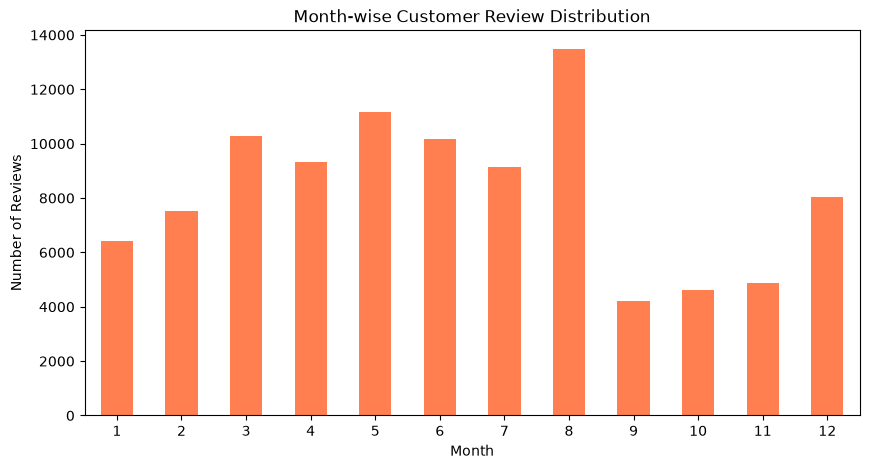

In [199]:
df_reviews['review_month'].value_counts().sort_index().plot(
    kind='bar',
    title='Month-wise Customer Review Distribution',
    xlabel='Month',
    ylabel='Number of Reviews',
    figsize=(10,5),
    color='coral'
)

plt.xticks(rotation=0)
plt.show()

#### Review Response Time Analysis

In [200]:
df_reviews['review_answer_timestamp'] = pd.to_datetime(
    df_reviews['review_answer_timestamp'],
    errors='coerce'
)

In [201]:
df_reviews['response_time_days'] = (
    df_reviews['review_answer_timestamp'] -
    df_reviews['review_creation_date']
).dt.total_seconds() / (24 * 60 * 60)

In [202]:
df_reviews['response_time_days'].mean()

np.float64(3.1489933993110615)

### Response Time Statistics

In [203]:
df_reviews['response_time_days'].describe()

count    99224.000000
mean         3.148993
std          9.890049
min          0.089225
25%          1.004870
50%          1.674948
75%          3.103565
max        518.699213
Name: response_time_days, dtype: float64

#### : Response Time Distribution Chart

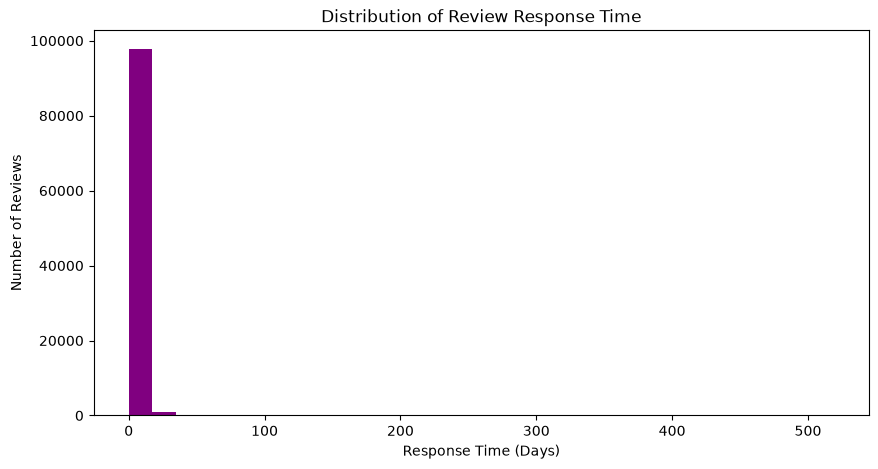

In [204]:
df_reviews['response_time_days'].plot(
    kind='hist',
    bins=30,
    title='Distribution of Review Response Time',
    xlabel='Response Time (Days)',
    ylabel='Number of Reviews',
    figsize=(10,5),
    color='purple'
)

plt.show()

### Delayed Review Responses

In [205]:
delayed_reviews = df_reviews[
    df_reviews['response_time_days'] > 7
]

delayed_reviews.shape[0]

4914

In [206]:
round((len(delayed_reviews) / len(df_reviews) * 100), 2)

4.95

### Final Review Dataset Validation

In [207]:
print("Total Reviews:", df_reviews.shape[0])
print("Unique Review IDs:", df_reviews['review_id'].nunique())
print("Unique Order IDs:", df_reviews['order_id'].nunique())
print("Average Rating:", round(df_reviews['review_score'].mean(), 2))
print("Average Response Time:", round(df_reviews['response_time_days'].mean(), 2))
print("Duplicate Rows:", df_reviews.duplicated().sum())

Total Reviews: 99224
Unique Review IDs: 98410
Unique Order IDs: 98673
Average Rating: 4.09
Average Response Time: 3.15
Duplicate Rows: 0


### Duplicate Review IDs investigate karte hain

In [208]:
df_reviews['review_id'].value_counts().head(10)

review_id
c444278834184f72b1484dfe47de7f97    3
308316408775d1600dad81bd3184556d    3
2d6ac45f859465b5c185274a1c929637    3
3415c9f764e478409e8e0660ae816dd2    3
4219a80ab469e3fc9901437b73da3f75    3
e44840754f12fad2b8646712121b349a    3
ddc52555ca27b0fe67d5255147682d2d    3
7b606b0d57b078384f0b58eac1d41d78    3
4d0e6dd087008d1f992d25ef6e1f619f    3
08528f70f579f0c830189efc523d2182    3
Name: count, dtype: int64

### Repeated Review ID investigate karna

In [209]:
df_reviews[
    df_reviews['review_id'] == 'c444278834184f72b1484dfe47de7f97'
]

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,review_category,comment_length,comment_type,review_year,review_month,response_time_days
2952,c444278834184f72b1484dfe47de7f97,df56136b8031ecd28e200bb18e6ddb2e,5,NaN,NaN,2017-02-08,2017-02-14 13:58:48,Positive,NaN,No Comment,2017,2,6.5825
43897,c444278834184f72b1484dfe47de7f97,566f53fc7d36fa366f7e221468121877,5,NaN,NaN,2017-02-08,2017-02-14 13:58:48,Positive,NaN,No Comment,2017,2,6.5825
95774,c444278834184f72b1484dfe47de7f97,8557dabbdacec1a9e250f5e70afe1eab,5,NaN,NaN,2017-02-08,2017-02-14 13:58:48,Positive,NaN,No Comment,2017,2,6.5825


In [210]:
duplicate_review_ids = df_reviews[
    df_reviews['review_id'].duplicated(keep=False)
]

print("Total records with repeated review IDs:",
      duplicate_review_ids.shape[0])

print("Number of repeated review IDs:",
      duplicate_review_ids['review_id'].nunique())

Total records with repeated review IDs: 1603
Number of repeated review IDs: 789


In [211]:
duplicate_review_ids.groupby('review_id')['order_id'].nunique().value_counts()

order_id
2    764
3     25
Name: count, dtype: int64


# Geolocation Dataset load

In [212]:
df_geolocation = pd.read_csv(
    'Olist_Dataset/olist_geolocation_dataset.csv'
)

df_geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [213]:
df_geolocation.shape

(1000163, 5)

In [214]:
df_geolocation.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 50.1 MB


In [215]:
df_geolocation.isnull().sum()

geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

### Check duplicate records

In [216]:
df_geolocation.duplicated().sum()

np.int64(261831)

### Duplicate percentage check karo

In [217]:
duplicate_percentage = (
    df_geolocation.duplicated().sum() /
    len(df_geolocation)
) * 100

round(duplicate_percentage, 2)

np.float64(26.18)

### Exact duplicates remove

In [218]:
df_geolocation_cleaned = df_geolocation.drop_duplicates()

df_geolocation_cleaned.shape

(738332, 5)

In [219]:
df_geolocation_cleaned.duplicated().sum()

np.int64(0)

### ZIP code analysis

In [220]:
df_geolocation_cleaned['geolocation_zip_code_prefix'].nunique()

19015

### State-wise geographical coverage

In [221]:
df_geolocation_cleaned['geolocation_state'].nunique()

27

In [222]:
df_geolocation_cleaned['geolocation_state'].value_counts()

geolocation_state
SP    285976
MG    101353
RJ     78836
RS     48093
PR     45059
SC     30191
BA     27720
GO     15601
PE     13162
ES     12632
CE      9541
MT      9374
DF      9080
MS      8594
PA      8551
MA      6277
PB      4787
RN      4014
PI      3592
AL      3415
TO      2977
SE      2653
RO      2523
AM      1986
AC      1039
AP       738
RR       568
Name: count, dtype: int64

### State-wise distribution chart

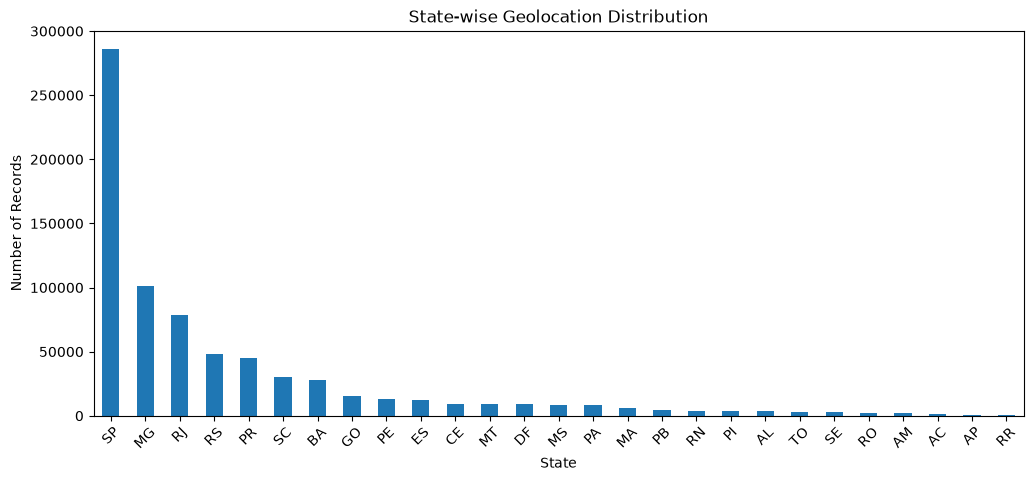

In [223]:
df_geolocation_cleaned['geolocation_state'].value_counts().plot(
    kind='bar',
    figsize=(12, 5),
    title='State-wise Geolocation Distribution',
    xlabel='State',
    ylabel='Number of Records'
)

plt.xticks(rotation=45)
plt.show() 

### Top 10 cities by geolocation records

In [224]:
top_cities = df_geolocation_cleaned[
    'geolocation_city'
].value_counts().head(10)

top_cities

geolocation_city
sao paulo         79927
rio de janeiro    35177
são paulo         19718
belo horizonte    19474
curitiba          11263
porto alegre       8702
salvador           8083
guarulhos          7411
brasilia           6919
osasco             4993
Name: count, dtype: int64

### City names normalize 

In [225]:
df_geolocation_cleaned['geolocation_city_cleaned'] = (
    df_geolocation_cleaned['geolocation_city']
    .str.normalize('NFKD')
    .str.encode('ascii', errors='ignore')
    .str.decode('utf-8')
    .str.strip()
    .str.lower()
)

In [226]:
df_geolocation_cleaned[
    df_geolocation_cleaned['geolocation_city'].str.contains(
        'são paulo|sao paulo',
        case=False,
        na=False
    )
]['geolocation_city_cleaned'].value_counts()

geolocation_city_cleaned
sao paulo                99645
sao paulo das missoes       21
sao paulo do potengi        15
morro de sao paulo           3
sao paulo de olivenca        2
Name: count, dtype: int64

In [227]:
df_geolocation_cleaned[
    'geolocation_city_cleaned'
].value_counts().head(10)

geolocation_city_cleaned
sao paulo                99646
rio de janeiro           35177
belo horizonte           19474
curitiba                 11263
brasilia                  8791
porto alegre              8702
salvador                  8084
guarulhos                 7411
sao bernardo do campo     5915
santo andre               5723
Name: count, dtype: int64

### Latitude and Longitude validation

In [228]:
df_geolocation_cleaned[
    ['geolocation_lat', 'geolocation_lng']
].describe()

,geolocation_lat,geolocation_lng
count,738332.000000,738332.000000
mean,-20.998353,-46.461098
std,5.892315,4.393705
min,-36.605374,-101.466766
25%,-23.603061,-48.867822
50%,-22.873588,-46.647278
75%,-19.923336,-43.836974
max,45.065933,121.105394


### Invalid coordinates identify 

In [229]:
invalid_coordinates = df_geolocation_cleaned[
    (df_geolocation_cleaned['geolocation_lat'] < -34) |
    (df_geolocation_cleaned['geolocation_lat'] > 6) |
    (df_geolocation_cleaned['geolocation_lng'] < -75) |
    (df_geolocation_cleaned['geolocation_lng'] > -30)
]

print("Invalid coordinate records:", invalid_coordinates.shape[0])

Invalid coordinate records: 27


In [230]:
invalid_coordinates.head(10)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,geolocation_city_cleaned
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP,bom retiro da esperanca
513631,28165,41.614052,-8.411675,vila nova de campos,RJ,vila nova de campos
513643,28155,-34.586422,-58.732101,santa maria,RJ,santa maria
513754,28155,42.439286,13.820214,santa maria,RJ,santa maria
514429,28333,38.381672,-6.328200,raposo,RJ,raposo
516682,28595,43.684961,-7.411080,portela,RJ,portela
538512,29654,29.409252,-98.484121,santo antônio do canaã,ES,santo antonio do canaa
538557,29654,21.657547,-101.466766,santo antonio do canaa,ES,santo antonio do canaa
585242,35179,25.995203,-98.078544,santana do paraíso,MG,santana do paraiso
585260,35179,25.995245,-98.078533,santana do paraiso,MG,santana do paraiso


### Invalid records ka state-wise count

In [231]:
invalid_coordinates['geolocation_state'].value_counts()

geolocation_state
RJ    5
PA    5
BA    4
RS    3
ES    2
MG    2
PR    2
SP    1
AL    1
PB    1
MT    1
Name: count, dtype: int64

### Cleaning decision

### Geolocation Data Quality Findings:
#### 1. Original dataset contains 1,000,163 records.
#### 2. 261,831 exact duplicate rows were removed.
#### 3. Cleaned dataset contains 738,332 records.
#### 4. 19,015 unique ZIP code prefixes.
#### 5. 27 states covered.
#### 6. City names normalized to handle accent differences.
#### 7. 27 records have coordinates outside the approximate
   #### geographical boundaries of Brazil.
#### 8. Potentially invalid coordinates were identified but
   #### not deleted.

## ZIP code-wise coordinate analysis

In [232]:
zip_coordinates = df_geolocation_cleaned.groupby(
    'geolocation_zip_code_prefix'
)[['geolocation_lat', 'geolocation_lng']].nunique()

zip_coordinates.head(10)

,geolocation_lat,geolocation_lng
geolocation_zip_code_prefix,,
1001,10,10
1002,6,6
1003,10,10
1004,14,14
1005,11,11
1006,7,7
1007,15,15
1008,12,12
1009,7,7


## ZIP code-wise average coordinates

In [233]:
zip_location = df_geolocation_cleaned.groupby(
    'geolocation_zip_code_prefix'
).agg(
    avg_latitude=('geolocation_lat', 'mean'),
    avg_longitude=('geolocation_lng', 'mean')
).reset_index()

zip_location.head(10)

,geolocation_zip_code_prefix,avg_latitude,avg_longitude
0,1001,-23.550227,-46.634039
1,1002,-23.547657,-46.634991
2,1003,-23.549000,-46.635582
3,1004,-23.549829,-46.634792
4,1005,-23.549547,-46.636406
5,1006,-23.550127,-46.636044
6,1007,-23.549962,-46.637204
7,1008,-23.546000,-46.635877
8,1009,-23.546891,-46.636498
9,1010,-23.546667,-46.635404


## Final ZIP location validation

In [234]:
print("Shape:", zip_location.shape)

print("Duplicate ZIP Codes:",
      zip_location['geolocation_zip_code_prefix'].duplicated().sum())

print("Missing Values:")
print(zip_location.isnull().sum())

Shape: (19015, 3)
Duplicate ZIP Codes: 0
Missing Values:
geolocation_zip_code_prefix    0
avg_latitude                   0
avg_longitude                  0
dtype: int64


### Geolocation Dataset Summary:
#### 1. Original records: 1,000,163
#### 2. Exact duplicate records: 261,831
#### 3. Cleaned records: 738,332
#### 4. Unique ZIP code prefixes: 19,015
#### 5. Unique states: 27
#### 6. City names normalized to handle accent differences.
#### 7. Potentially invalid coordinates identified: 27
#### 8. ZIP code-wise average latitude and longitude calculated.
#### 9. Final aggregated dataset: 19,015 rows and 3 columns.
#### 10. No missing values or duplicate ZIP codes in final dataset.

# Data Integration (Combining Datasets).

In [235]:
df_customers_geo = df_customer.merge(
    zip_location,
    left_on='customer_zip_code_prefix',
    right_on='geolocation_zip_code_prefix',
    how='left'
)

df_customers_geo.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,geolocation_zip_code_prefix,avg_latitude,avg_longitude
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,14409.0,-20.499273,-47.396658
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,9790.0,-23.728396,-46.542250
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,1151.0,-23.531309,-46.656690
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,8775.0,-23.500670,-46.186348
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,13056.0,-22.975708,-47.143140


## Merge validation

In [236]:
print("Original Customers:", df_customer.shape)
print("Merged Customers:", df_customers_geo.shape)

print("\nMissing Latitude:")
print(df_customers_geo['avg_latitude'].isnull().sum())

print("\nMissing Longitude:")
print(df_customers_geo['avg_longitude'].isnull().sum())

Original Customers: (99441, 5)
Merged Customers: (99441, 8)

Missing Latitude:
278

Missing Longitude:
278


## Missing ZIP codes identify 

In [237]:
missing_geo = df_customers_geo[
    df_customers_geo['avg_latitude'].isnull()
]

missing_geo[
    ['customer_zip_code_prefix', 'customer_city', 'customer_state']
].head(10)

,customer_zip_code_prefix,customer_city,customer_state
354,72300,brasilia,DF
382,11547,cubatao,SP
877,64605,picos,PI
1218,72465,brasilia,DF
1272,7729,caieiras,SP
1309,72904,santo antonio do descoberto,GO
1421,35408,glaura,MG
1742,78554,sinop,MT
2095,73369,brasilia,DF
2166,8980,nossa senhora do remedio,SP


## Check unique unmatched ZIP codes

In [238]:
print(
    "Unmatched Unique ZIP Codes:",
    missing_geo['customer_zip_code_prefix'].nunique()
)

Unmatched Unique ZIP Codes: 157


In [239]:
missing_geo['customer_zip_code_prefix'].value_counts().head(10)

customer_zip_code_prefix
70686    15
72005    13
71919    10
73255     7
72300     6
73369     5
71884     5
72002     5
73401     5
71676     4
Name: count, dtype: int64

In [240]:
df_sellers_geo = df_sellers.merge(
    zip_location,
    left_on='seller_zip_code_prefix',
    right_on='geolocation_zip_code_prefix',
    how='left'
)

df_sellers_geo.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state,geolocation_zip_code_prefix,avg_latitude,avg_longitude
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP,13023.0,-22.893317,-47.060596
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP,13844.0,-22.383375,-46.948142
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ,20031.0,-22.909446,-43.180240
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP,4195.0,-23.657118,-46.612730
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP,12914.0,-22.964546,-46.534214


### Seller merge validation

In [241]:
print("Original Sellers:", df_sellers.shape)
print("Merged Sellers:", df_sellers_geo.shape)

print("\nMissing Latitude:")
print(df_sellers_geo['avg_latitude'].isnull().sum())

print("\nMissing Longitude:")
print(df_sellers_geo['avg_longitude'].isnull().sum())

Original Sellers: (3095, 4)
Merged Sellers: (3095, 7)

Missing Latitude:
7

Missing Longitude:
7


## Identify unmatched sellers

In [242]:
missing_seller_geo = df_sellers_geo[
    df_sellers_geo['avg_latitude'].isnull()
]

missing_seller_geo[
    ['seller_zip_code_prefix', 'seller_city', 'seller_state']
]

,seller_zip_code_prefix,seller_city,seller_state
473,82040,curitiba,PR
791,91901,porto alegre,RS
1672,72580,brasilia,DF
1931,2285,sao paulo,SP
2182,7412,aruja,SP
2986,71551,brasilia,DF
3028,37708,pocos de caldas,MG


In [243]:
missing_seller_geo = df_sellers_geo[
    df_sellers_geo['avg_latitude'].isnull()
]

missing_seller_geo[
    ['seller_zip_code_prefix', 'seller_city', 'seller_state']
]

,seller_zip_code_prefix,seller_city,seller_state
473,82040,curitiba,PR
791,91901,porto alegre,RS
1672,72580,brasilia,DF
1931,2285,sao paulo,SP
2182,7412,aruja,SP
2986,71551,brasilia,DF
3028,37708,pocos de caldas,MG


## Master Sales Dataset

In [244]:
df_master = df_items.merge(
    df_orders,
    on='order_id',
    how='left'
)

print(df_master.shape)

(112650, 18)


### Customer details add karna

In [245]:
df_master = df_master.merge(
    df_customer,
    on='customer_id',
    how='left'
)

print(df_master.shape)

(112650, 22)


## Product details merge

In [246]:
df_master = df_master.merge(
    df_products,
    on='product_id',
    how='left'
)

print(df_master.shape)

(112650, 36)


## Seller details merge

In [247]:
df_master = df_master.merge(
    df_sellers_geo,
    on='seller_id',
    how='left'
)

print(df_master.shape)

(112650, 42)


## Payment details

In [248]:
payments_summary = df_payments.groupby('order_id').agg(
    total_payment_value=('payment_value', 'sum'),
    payment_count=('payment_sequential', 'count'),
    max_installments=('payment_installments', 'max')
).reset_index()

print(payments_summary.shape)

(99440, 4)


## merge Payments to Master Dataset 

In [249]:
df_master = df_master.merge(
    payments_summary,
    on='order_id',
    how='left'
)

print(df_master.shape)

(112650, 45)


## Order Reviews.

In [250]:
review_summary = df_reviews.groupby('order_id').agg(
    avg_review_score=('review_score', 'mean'),
    review_count=('review_score', 'count')
).reset_index()

print(review_summary.shape)

(98673, 3)


## Final merge

In [251]:
df_master = df_master.merge(
    review_summary,
    on='order_id',
    how='left'
)

print(df_master.shape)

(112650, 47)


In [252]:
print("Duplicate Rows:", df_master.duplicated().sum())

Duplicate Rows: 0


In [253]:
missing_values = df_master.isnull().sum()

missing_values[missing_values > 0].sort_values(ascending=False)

order_delivered_customer_date    2454
delivery_difference              2454
delivery_days                    2454
product_description_lenght       1603
product_photos_qty               1603
product_category_name            1603
product_name_lenght              1603
product_category_name_english    1603
order_delivered_carrier_date     1194
avg_review_score                  942
review_count                      942
avg_latitude                      253
avg_longitude                     253
geolocation_zip_code_prefix       253
product_weight_g                   18
product_volume_cm3                 18
product_length_cm                  18
product_width_cm                   18
product_height_cm                  18
product_width_cleaned              17
product_height_cleaned             17
product_length_cleaned             17
product_weight_cleaned             17
order_approved_at                  15
total_payment_value                 3
max_installments                    3
payment_coun

## Missing product details investigate 

In [254]:
missing_products = df_master[
    df_master['product_category_name'].isnull()
]

print("Missing Product IDs:",
      missing_products['product_id'].isnull().sum())

print("Missing Product Categories:",
      missing_products['product_category_name'].isnull().sum())

Missing Product IDs: 0
Missing Product Categories: 1603


In [255]:
missing_products[
    ['product_id', 'product_category_name',
     'product_category_name_english',
     'product_weight_g']
].head(10)

,product_id,product_category_name,product_category_name_english,product_weight_g
123,ff6caf9340512b8bf6d2a2a6df032cfa,NaN,NaN,200.0
125,a9c404971d1a5b1cbc2e4070e02731fd,NaN,NaN,700.0
132,5a848e4ab52fd5445cdc07aab1c40e48,NaN,NaN,400.0
142,41eee23c25f7a574dfaf8d5c151dbb12,NaN,NaN,200.0
171,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,2200.0
370,76d1a1a9d21ab677a61c3ae34b1b352f,NaN,NaN,550.0
378,fbb1cfc2810efabf3235eccf4530f4ae,NaN,NaN,800.0
434,5a848e4ab52fd5445cdc07aab1c40e48,NaN,NaN,400.0
454,9f69acd4da62618a3f6365b732d00ccd,NaN,NaN,850.0
456,ea11e700a343582ad56e4c70e966cb36,NaN,NaN,26000.0


## Check remaining product information

In [256]:
missing_products[
    ['product_name_lenght',
     'product_description_lenght',
     'product_photos_qty',
     'product_weight_g',
     'product_length_cm',
     'product_height_cm',
     'product_width_cm']
].isnull().sum()

product_name_lenght           1603
product_description_lenght    1603
product_photos_qty            1603
product_weight_g                17
product_length_cm               17
product_height_cm               17
product_width_cm                17
dtype: int64

## Missing payment records investigate

In [257]:
missing_payments = df_master[
    df_master['total_payment_value'].isnull()
]

print("Missing Payment Rows:", len(missing_payments))

print("Unique Orders:",
      missing_payments['order_id'].nunique())

print("Order Status:")
print(missing_payments['order_status'].value_counts())

Missing Payment Rows: 3
Unique Orders: 1
Order Status:
order_status
delivered    3
Name: count, dtype: int64


In [258]:
missing_order_id = missing_payments['order_id'].unique()[0]

print("Missing Order ID:", missing_order_id)

print(
    df_payments[df_payments['order_id'] == missing_order_id]
)

Missing Order ID: bfbd0f9bdef84302105ad712db648a6c
Empty DataFrame
Columns: [order_id, payment_sequential, payment_type, payment_installments, payment_value]
Index: []


### Missing review records check

In [259]:
missing_reviews = df_master[
    df_master['avg_review_score'].isnull()
]

print("Missing Review Rows:", len(missing_reviews))

print("Unique Orders:",
      missing_reviews['order_id'].nunique())

print("Order Status:")
print(missing_reviews['order_status'].value_counts())

Missing Review Rows: 942
Unique Orders: 749
Order Status:
order_status
delivered     827
shipped        86
canceled       17
processing      6
invoiced        6
Name: count, dtype: int64


### Missing customer geolocation check

In [260]:
missing_customer_geo = df_master[
    df_master['avg_latitude'].isnull()
]

print("Missing Geo Rows:", len(missing_customer_geo))

print("Unique Customer ZIP Codes:",
      missing_customer_geo['customer_zip_code_prefix'].nunique())

Missing Geo Rows: 253
Unique Customer ZIP Codes: 210


## Final Master Dataset validation

In [261]:
print("Final Dataset Shape:", df_master.shape)

print("Total Orders:", df_master['order_id'].nunique())

print("Total Products:", df_master['product_id'].nunique())

print("Total Sellers:", df_master['seller_id'].nunique())

print("Duplicate Rows:", df_master.duplicated().sum())

Final Dataset Shape: (112650, 47)
Total Orders: 98666
Total Products: 32951
Total Sellers: 3095
Duplicate Rows: 0


In [262]:
df_master.to_csv(
    'Olist_Dataset/olist_master_dataset.csv',
    index=False
)

print("Master Dataset Saved Successfully!")

Master Dataset Saved Successfully!


# Python Business Analysis

# Overall Sales Performance Analysis
## Calculate Total Revenue

In [263]:
total_revenue = df_master['price'].sum()

print("Total Revenue: R$", round(total_revenue, 2))

Total Revenue: R$ 13591643.7


## Calculate Total Orders

In [264]:
total_orders = df_master['order_id'].nunique()

print("Total Orders:", total_orders)

Total Orders: 98666


## Calculate Average Order Value (AOV)

In [265]:
average_order_value = total_revenue / total_orders

print("Average Order Value: R$", round(average_order_value, 2))

Average Order Value: R$ 137.75


## Calculate Total Unique Customers

In [266]:
total_customers = df_master['customer_unique_id'].nunique()

print("Total Unique Customers:", total_customers)

Total Unique Customers: 95420


## Calculate Total Products Sold

In [267]:
total_products_sold = df_master['order_item_id'].count()

print("Total Products Sold:", total_products_sold)

Total Products Sold: 112650


## Monthly Revenue Analysis

In [268]:
monthly_revenue = df_master.groupby(
    df_master['order_purchase_timestamp'].dt.to_period('M')
)['price'].sum()

print(monthly_revenue)

order_purchase_timestamp
2016-09        267.36
2016-10      49507.66
2016-12         10.90
2017-01     120312.87
2017-02     247303.02
2017-03     374344.30
2017-04     359927.23
2017-05     506071.14
2017-06     433038.60
2017-07     498031.48
2017-08     573971.68
2017-09     624401.69
2017-10     664219.43
2017-11    1010271.37
2017-12     743914.17
2018-01     950030.36
2018-02     844178.71
2018-03     983213.44
2018-04     996647.75
2018-05     996517.68
2018-06     865124.31
2018-07     895507.22
2018-08     854686.33
2018-09        145.00
Freq: M, Name: price, dtype: float64


## Monthly Revenue Trend Chart

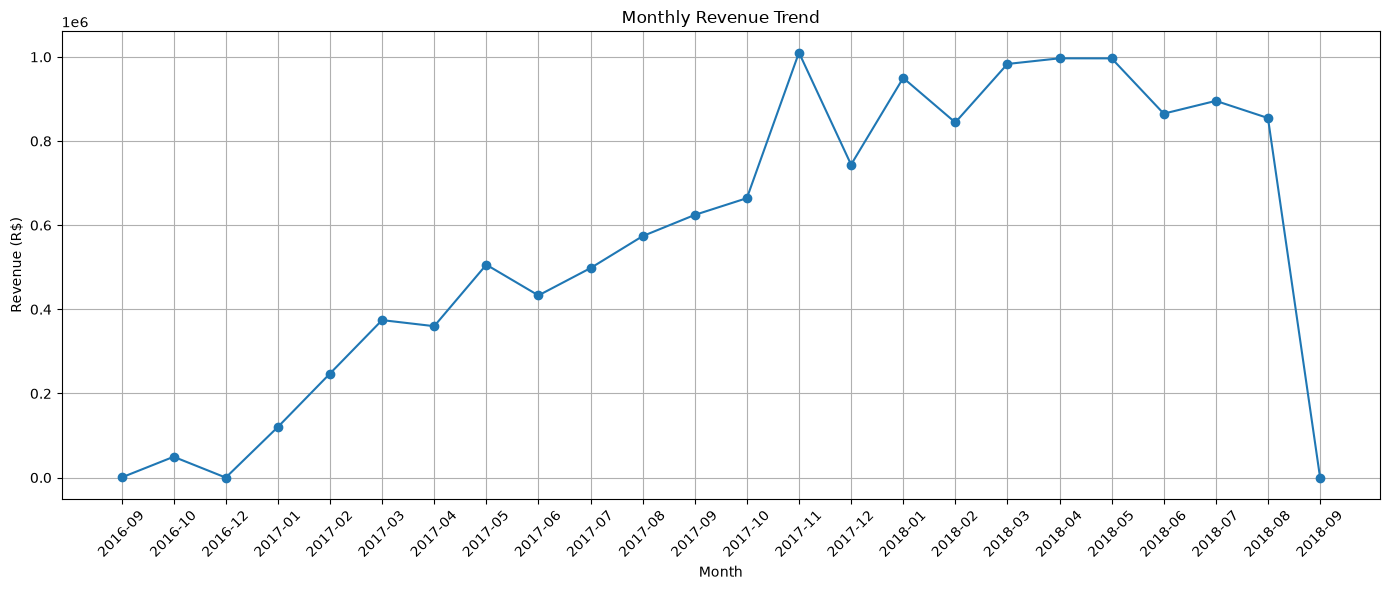

In [269]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (R$)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## Year-wise Revenue Analysis

In [270]:
yearly_revenue = df_master.groupby(
    df_master['order_purchase_timestamp'].dt.year
)['price'].sum()

print(yearly_revenue)

order_purchase_timestamp
2016      49785.92
2017    6155806.98
2018    7386050.80
Name: price, dtype: float64


### Year-wise Revenue Chart

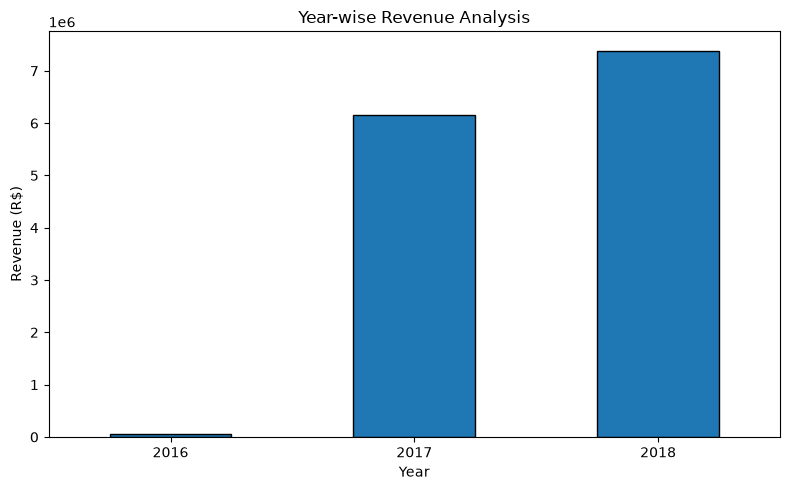

In [271]:
plt.figure(figsize=(8, 5))

yearly_revenue.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Year-wise Revenue Analysis')
plt.xlabel('Year')
plt.ylabel('Revenue (R$)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Top 10 Best-Selling Product Categories

In [272]:
top_categories = df_master.groupby(
    'product_category_name_english'
)['price'].sum().sort_values(
    ascending=False
).head(10)

print(top_categories)

product_category_name_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
Name: price, dtype: float64


## : Visualize Top 10 Categories

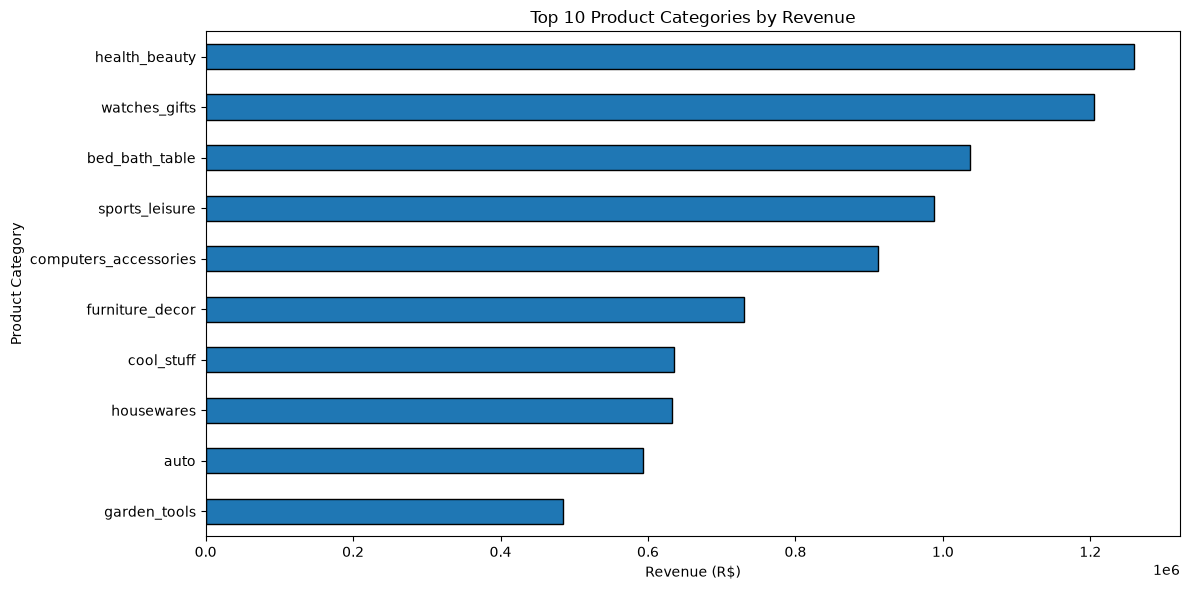

In [273]:
plt.figure(figsize=(12, 6))

top_categories.sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Revenue (R$)')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()

## Top 10 Product Categories by Number of Orders

In [274]:
top_categories_orders = df_master.groupby(
    'product_category_name_english'
)['order_id'].nunique().sort_values(
    ascending=False
).head(10)

print(top_categories_orders)

product_category_name_english
bed_bath_table           9417
health_beauty            8836
sports_leisure           7720
computers_accessories    6689
furniture_decor          6449
housewares               5884
watches_gifts            5624
telephony                4199
auto                     3897
toys                     3886
Name: order_id, dtype: int64


## Visualize Top 10 Categories by Orders

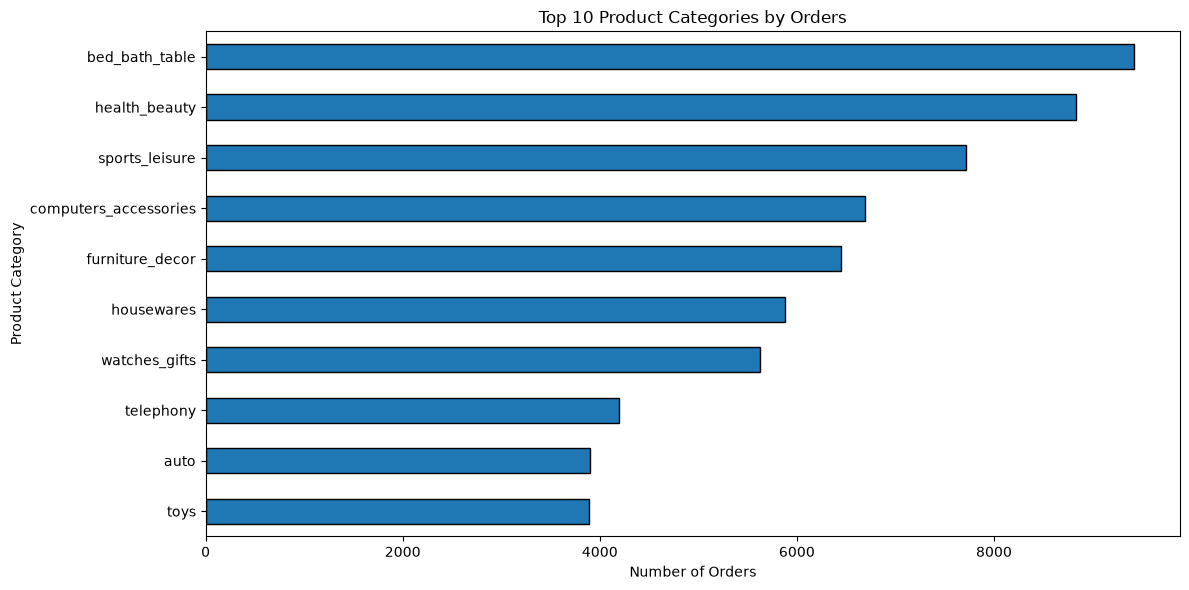

In [275]:
plt.figure(figsize=(12, 6))

top_categories_orders.sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Top 10 Product Categories by Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()

## Repeat vs One-Time Customers

In [276]:
customer_orders = df_master.groupby(
    'customer_unique_id'
)['order_id'].nunique()

print(customer_orders.value_counts().sort_index())

order_id
1     92507
2      2673
3       192
4        29
5         9
6         5
7         3
9         1
16        1
Name: count, dtype: int64


## Customer Distribution Chart

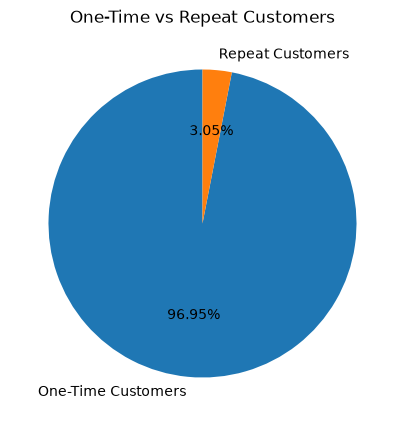

In [277]:
customer_type = customer_orders.value_counts()

one_time = customer_type.loc[1]
repeat = customer_type.drop(index=1).sum()

plt.figure(figsize=(7, 5))

plt.pie(
    [one_time, repeat],
    labels=['One-Time Customers', 'Repeat Customers'],
    autopct='%1.2f%%',
    startangle=90
)

plt.title('One-Time vs Repeat Customers')
plt.show()

## Average Orders per Customer

In [278]:
avg_orders_per_customer = customer_orders.mean()

print(
    "Average Orders per Customer:",
    round(avg_orders_per_customer, 2)
)

Average Orders per Customer: 1.03


## Top 10 Customers by Number of Orders

In [279]:
top_customers = customer_orders.sort_values(
    ascending=False
).head(10)

print(top_customers)

customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    16
3e43e6105506432c953e165fb2acf44c     9
1b6c7548a2a1f9037c1fd3ddfed95f33     7
6469f99c1f9dfae7733b25662e7f1782     7
ca77025e7201e3b30c44b472ff346268     7
47c1a3033b8b77b3ab6e109eb4d5fdf3     6
12f5d6e1cbf93dafd9dcc19095df0b3d     6
63cfc61cee11cbe306bff5857d00bfe4     6
dc813062e0fc23409cd255f7f53c7074     6
f0e310a6839dce9de1638e0fe5ab282a     6
Name: order_id, dtype: int64


## State-wise Revenue Analysis

In [280]:
state_revenue = df_master.groupby(
    'customer_state'
)['price'].sum().sort_values(ascending=False)

print(state_revenue.head(10))

customer_state
SP    5202955.05
RJ    1824092.67
MG    1585308.03
RS     750304.02
PR     683083.76
SC     520553.34
BA     511349.99
DF     302603.94
GO     294591.95
ES     275037.31
Name: price, dtype: float64


## Visualize State-wise Revenue

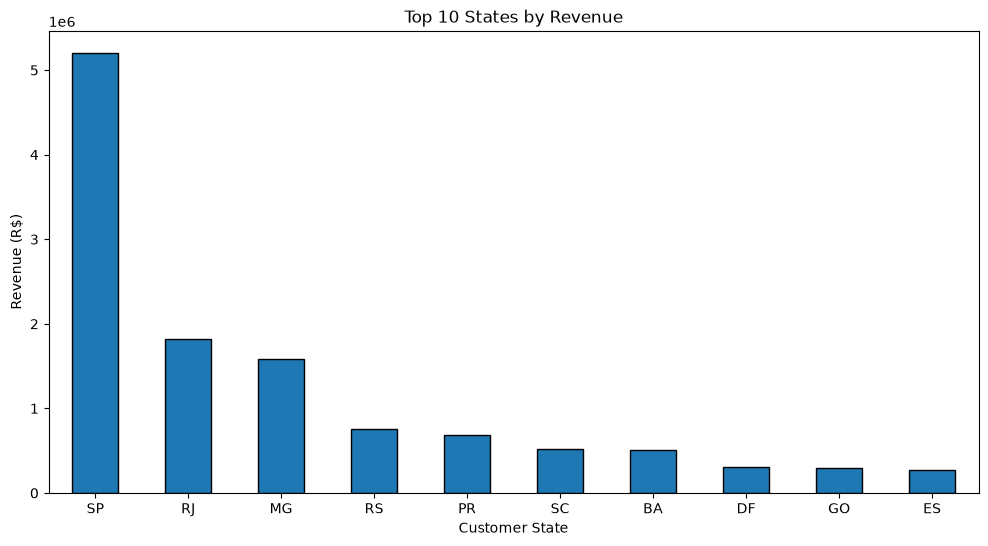

In [281]:
plt.figure(figsize=(12,6))

state_revenue.head(10).plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Top 10 States by Revenue')
plt.xlabel('Customer State')
plt.ylabel('Revenue (R$)')
plt.xticks(rotation=0)
plt.show()

## Average Order Value by State

In [282]:
state_aov = df_master.groupby('customer_state').agg(
    total_revenue=('price', 'sum'),
    total_orders=('order_id', 'nunique')
)

state_aov['AOV'] = (
    state_aov['total_revenue'] / state_aov['total_orders']
)

state_aov = state_aov.sort_values(
    by='AOV', ascending=False
)

print(state_aov.head(10))

                total_revenue  total_orders         AOV
customer_state                                         
PB                  115268.08           532  216.669323
AP                   13474.30            68  198.151471
AC                   15982.95            81  197.320370
AL                   80314.81           411  195.413163
RO                   46140.64           247  186.804211
PA                  178947.81           970  184.482278
TO                   49621.74           279  177.855699
PI                   86914.08           493  176.296308
MT                  156453.53           903  173.259723
RN                   83034.98           482  172.271743


## Visualize Top 10 States by AOV

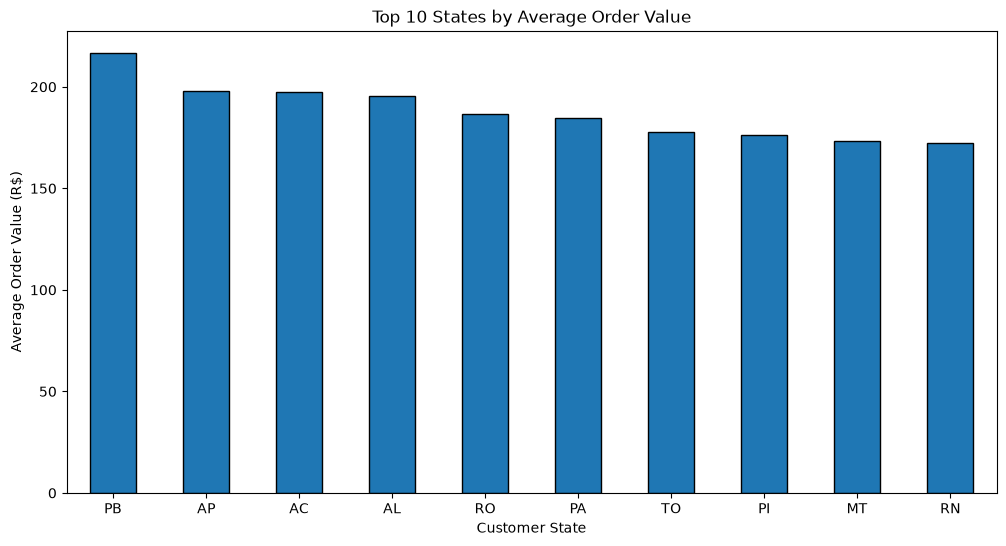

In [283]:
plt.figure(figsize=(12,6))

state_aov['AOV'].head(10).plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Top 10 States by Average Order Value')
plt.xlabel('Customer State')
plt.ylabel('Average Order Value (R$)')
plt.xticks(rotation=0)
plt.show()

## Payment Method Analysis

In [284]:
payment_analysis = df_payments.groupby('payment_type').agg(
    total_revenue=('payment_value', 'sum'),
    total_orders=('order_id', 'nunique')
).sort_values(by='total_revenue', ascending=False)

print(payment_analysis)

              total_revenue  total_orders
payment_type                             
credit_card     12542084.19         76505
boleto           2869361.27         19784
voucher           379436.87          3866
debit_card        217989.79          1528
not_defined            0.00             3


### Payment Method Revenue Chart

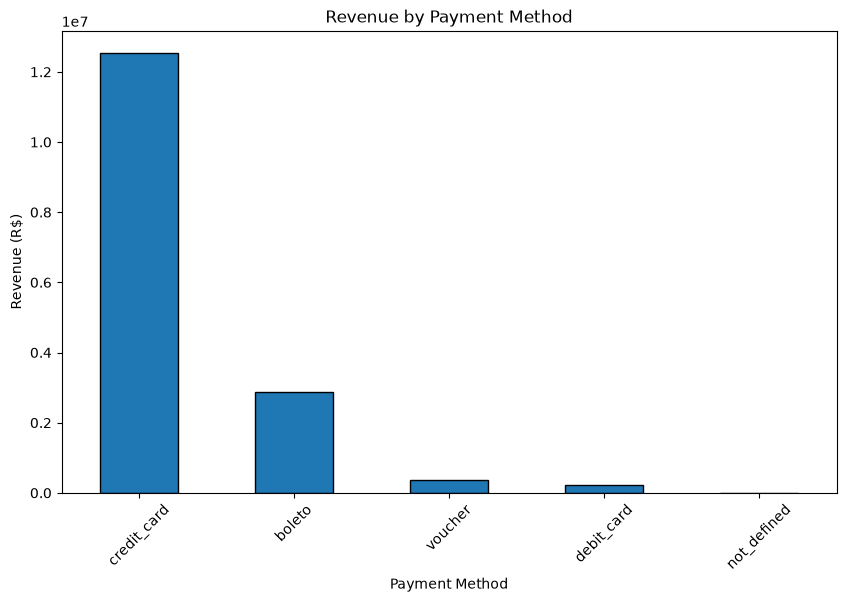

In [285]:
plt.figure(figsize=(10,6))

payment_analysis['total_revenue'].plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Revenue (R$)')
plt.xticks(rotation=45)
plt.show()

### Average Review Score by Product Category

In [286]:
category_reviews = df_master.groupby(
    'product_category_name_english'
)['avg_review_score'].mean().sort_values(
    ascending=False
)

print(category_reviews.head(10))

product_category_name_english
cds_dvds_musicals                        4.642857
fashion_childrens_clothes                4.500000
books_general_interest                   4.446266
costruction_tools_tools                  4.444444
flowers                                  4.419355
books_imported                           4.400000
books_technical                          4.363636
luggage_accessories                      4.315257
food_drink                               4.312274
small_appliances_home_oven_and_coffee    4.302632
Name: avg_review_score, dtype: float64


### : Visualize Top 10 Categories by Review Score

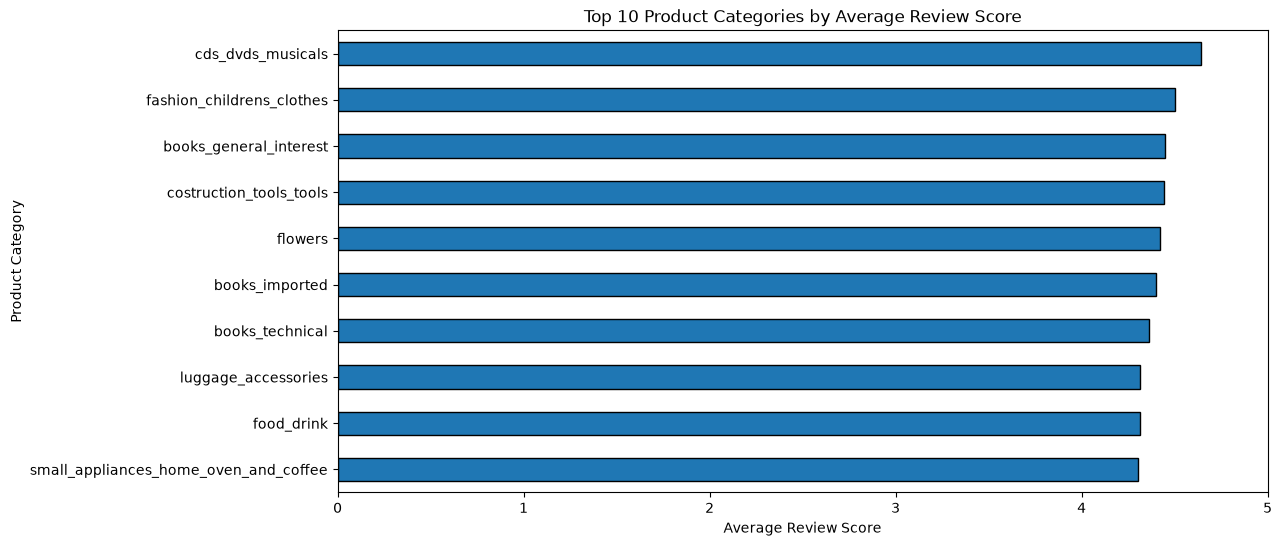

In [287]:
plt.figure(figsize=(12,6))

category_reviews.head(10).sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Top 10 Product Categories by Average Review Score')
plt.xlabel('Average Review Score')
plt.ylabel('Product Category')
plt.xlim(0, 5)
plt.show()

## Lowest 10 Product Categories by Review Score

In [288]:
lowest_categories = category_reviews.sort_values(
    ascending=True
).head(10)

print(lowest_categories)

product_category_name_english
security_and_services                2.500000
diapers_and_hygiene                  3.256410
pc_gamer                             3.333333
office_furniture                     3.488968
home_comfort_2                       3.629630
fashion_male_clothing                3.641221
fixed_telephony                      3.681992
party_supplies                       3.767442
fashio_female_clothing               3.781250
furniture_mattress_and_upholstery    3.815789
Name: avg_review_score, dtype: float64


## Visualize Lowest 10 Categories

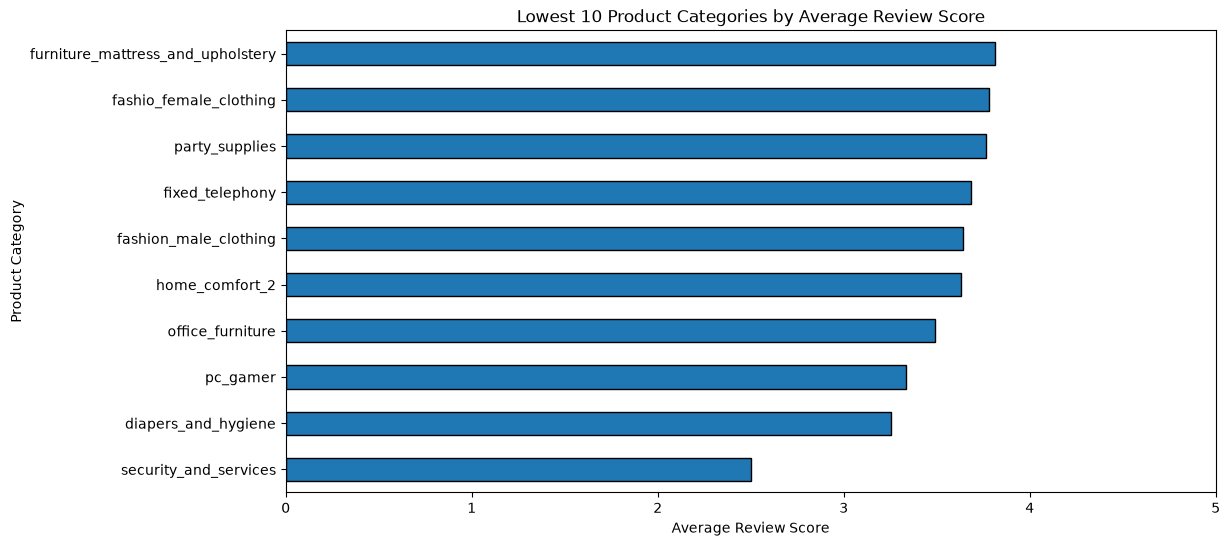

In [289]:
plt.figure(figsize=(12,6))

lowest_categories.sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Lowest 10 Product Categories by Average Review Score')
plt.xlabel('Average Review Score')
plt.ylabel('Product Category')
plt.xlim(0, 5)
plt.show()

## Delivery Time vs Customer Satisfaction

In [290]:
df_orders['delivery_status'] = np.where(
    df_orders['delivery_difference'] > 0, 'Late',
    np.where(
        df_orders['delivery_difference'] < 0, 'Early',
        'On Time'
    )
)

print(df_orders['delivery_status'].value_counts())

delivery_status
Early      88649
Late        6535
On Time     4257
Name: count, dtype: int64


In [291]:
print(df_orders.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_year', 'order-month', 'delivery_days', 'delivery_difference', 'delivery_status']


### Delivery Status vs Review Score

In [292]:
delivery_review = df_orders[
    ['order_id', 'delivery_status']
].merge(
    review_summary,
    on='order_id',
    how='left'
)

delivery_satisfaction = delivery_review.groupby(
    'delivery_status'
)['avg_review_score'].mean()

print(delivery_satisfaction)

delivery_status
Early      4.294151
Late       2.271937
On Time    2.461800
Name: avg_review_score, dtype: float64


### Visualize Delivery vs Satisfaction

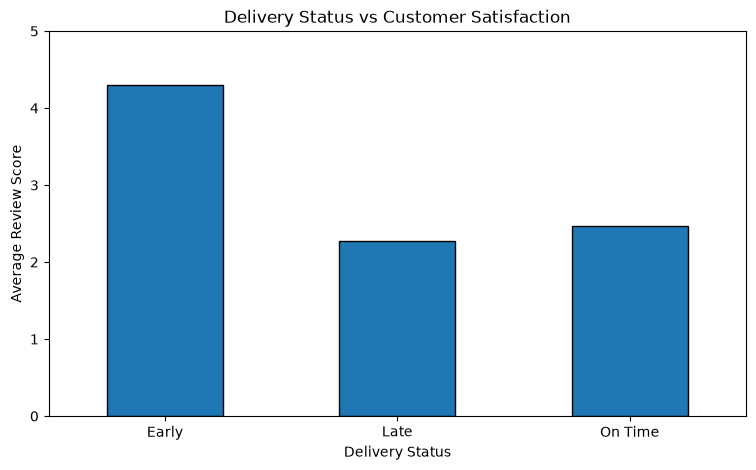

In [293]:
plt.figure(figsize=(9,5))

delivery_satisfaction.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Delivery Status vs Customer Satisfaction')
plt.xlabel('Delivery Status')
plt.ylabel('Average Review Score')
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.show()

## Seller Performance Analysis

In [294]:
seller_revenue = df_master.groupby('seller_id').agg(
    total_revenue=('price', 'sum'),
    total_orders=('order_id', 'nunique')
).sort_values(
    by='total_revenue',
    ascending=False
)

print(seller_revenue.head(10))

                                  total_revenue  total_orders
seller_id                                                    
4869f7a5dfa277a7dca6462dcf3b52b2      229472.63          1132
53243585a1d6dc2643021fd1853d8905      222776.05           358
4a3ca9315b744ce9f8e9374361493884      200472.92          1806
fa1c13f2614d7b5c4749cbc52fecda94      194042.03           585
7c67e1448b00f6e969d365cea6b010ab      187923.89           982
7e93a43ef30c4f03f38b393420bc753a      176431.87           336
da8622b14eb17ae2831f4ac5b9dab84a      160236.57          1314
7a67c85e85bb2ce8582c35f2203ad736      141745.53          1160
1025f0e2d44d7041d6cf58b6550e0bfa      138968.55           915
955fee9216a65b617aa5c0531780ce60      135171.70          1287


### Visualize Top 10 Sellers by Revenue

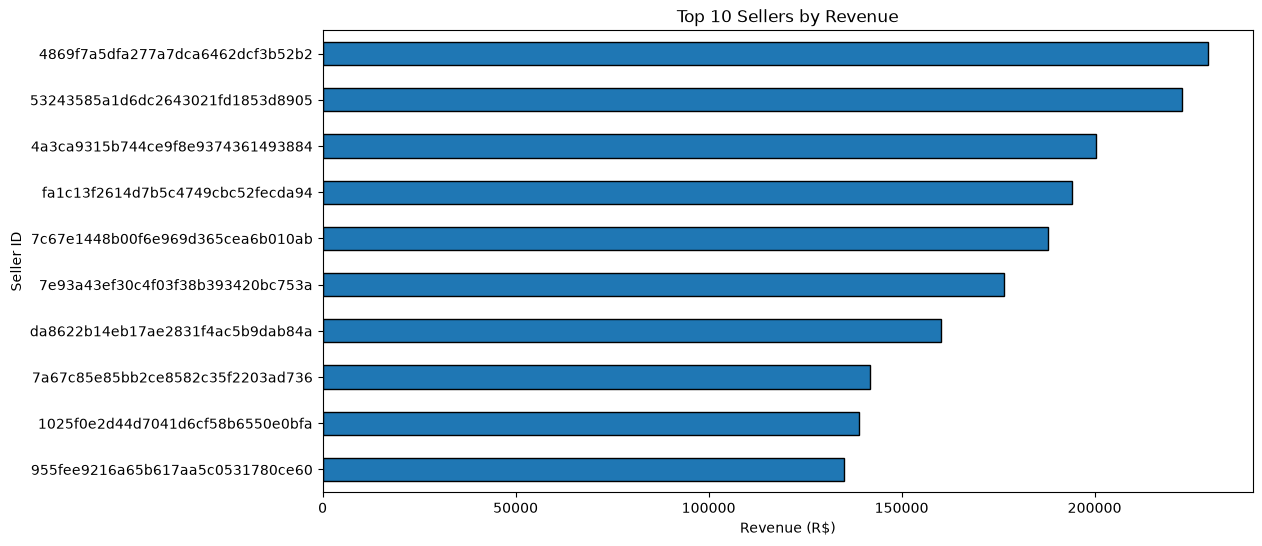

In [295]:
plt.figure(figsize=(12,6))

seller_revenue['total_revenue'].head(10).sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Top 10 Sellers by Revenue')
plt.xlabel('Revenue (R$)')
plt.ylabel('Seller ID')
plt.show()

### Top 10 Sellers by Number of Orders

In [296]:
top_sellers_orders = seller_revenue.sort_values(
    by='total_orders',
    ascending=False
).head(10)

print(top_sellers_orders)

                                  total_revenue  total_orders
seller_id                                                    
6560211a19b47992c3666cc44a7e94c0      123304.83          1854
4a3ca9315b744ce9f8e9374361493884      200472.92          1806
cc419e0650a3c5ba77189a1882b7556a      104288.42          1706
1f50f920176fa81dab994f9023523100      106939.21          1404
da8622b14eb17ae2831f4ac5b9dab84a      160236.57          1314
955fee9216a65b617aa5c0531780ce60      135171.70          1287
7a67c85e85bb2ce8582c35f2203ad736      141745.53          1160
ea8482cd71df3c1969d7b9473ff13abc       37177.52          1146
4869f7a5dfa277a7dca6462dcf3b52b2      229472.63          1132
3d871de0142ce09b7081e2b9d1733cb1       94914.20          1080


### Visualize Top 10 Sellers by Orders

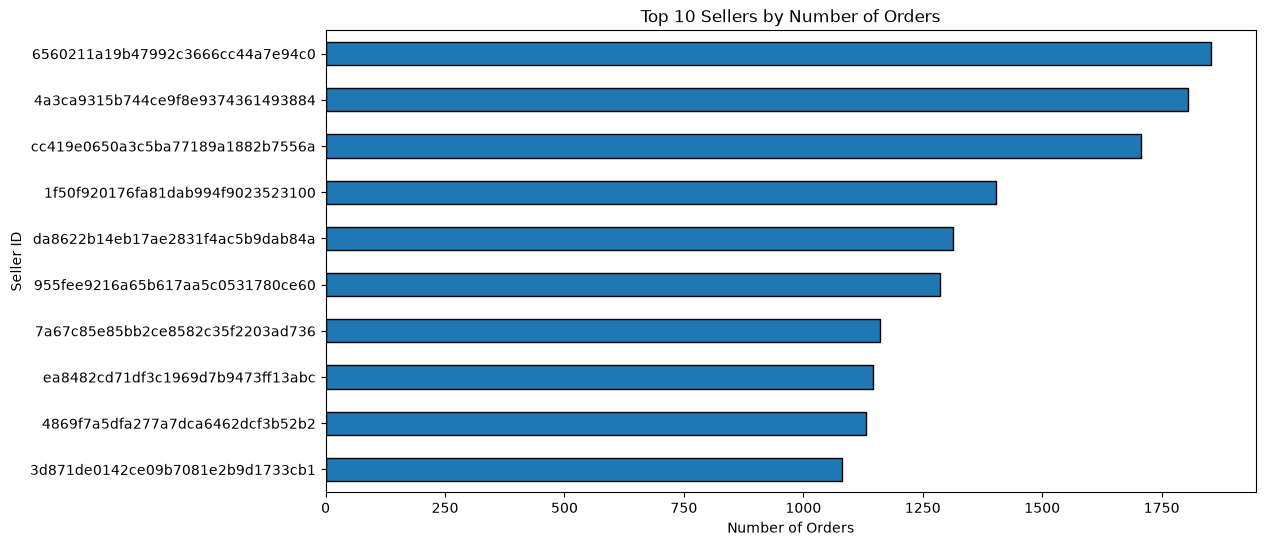

In [297]:
plt.figure(figsize=(12,6))

top_sellers_orders['total_orders'].sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Top 10 Sellers by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Seller ID')
plt.show()

### Seller Average Order Value

In [298]:
seller_revenue['seller_AOV'] = (
    seller_revenue['total_revenue'] /
    seller_revenue['total_orders']
)

top_sellers_aov = seller_revenue.sort_values(
    by='seller_AOV',
    ascending=False
).head(10)

print(top_sellers_aov)

                                  total_revenue  total_orders   seller_AOV
seller_id                                                                 
80ceebb4ee9b31afb6c6a916a574a1e2        6729.00             1  6729.000000
ee27a8f15b1dded4d213a468ba4eb391        6499.00             1  6499.000000
b37c4c02bda3161a7546a4e6d222d5b2       24075.00             4  6018.750000
585175ec331ea177fa47199e39a6170a        3549.00             1  3549.000000
abe021b01ba992245271b9aa422032df        6720.00             2  3360.000000
a00824eb9093d40e589b940ec45c4eb0        9399.97             3  3133.323333
e2a1ac9bf33e5549a2a4f834e70df2f8       14999.45             5  2999.890000
e908c0f3646e8b60375734a350d95d71        2951.00             1  2951.000000
d63c73efd41eb002280e7ec831424edb        5598.00             2  2799.000000
1444c08e64d55fb3c25f0f09c07ffcf2        2749.00             1  2749.000000


## Seller AOV with Minimum 50 Orders

In [299]:
reliable_sellers = seller_revenue[
    seller_revenue['total_orders'] >= 50
].sort_values(
    by='seller_AOV',
    ascending=False
).head(10)

print(reliable_sellers)

                                  total_revenue  total_orders  seller_AOV
seller_id                                                                
e882b2a25a10b9c057cc49695f222c19       51057.54            57  895.746316
17f51e7198701186712e53a39c564617       48019.00            56  857.482143
966cb4760537b1404caedd472cc610a5       51286.05            75  683.814000
04308b1ee57b6625f47df1d56f00eedf       60130.60            94  639.687234
53243585a1d6dc2643021fd1853d8905      222776.05           358  622.279469
834f3294fba9f932f56edc879193f925       39907.50            66  604.659091
7681ef142fd2c19048da7430856b5588       31941.81            59  541.386610
eeb6de78f79159600292e314a77cbd18       43739.84            83  526.986024
7e93a43ef30c4f03f38b393420bc753a      176431.87           336  525.094851
712e6ed8aa4aa1fa65dab41fed5737e4       39815.00            79  503.987342


### Visualize Top 10 Sellers by AOV

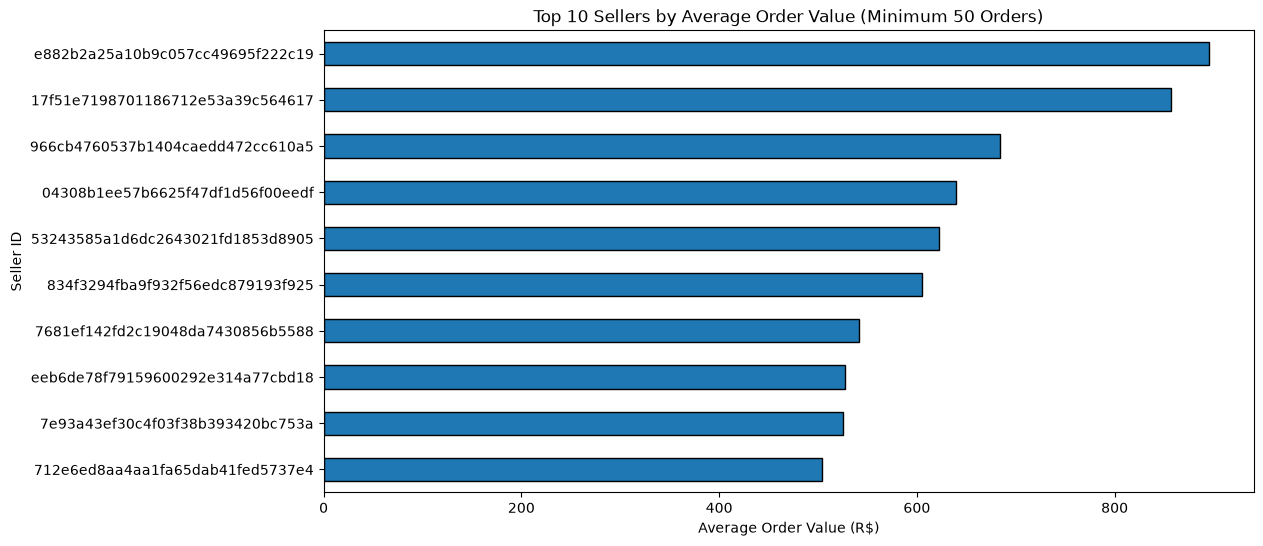

In [300]:
plt.figure(figsize=(12,6))

reliable_sellers['seller_AOV'].sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Top 10 Sellers by Average Order Value (Minimum 50 Orders)')
plt.xlabel('Average Order Value (R$)')
plt.ylabel('Seller ID')
plt.show()

### Monthly Order Volume Analysis

In [305]:
monthly_orders = df_master.groupby(
    df_master['order_purchase_timestamp'].dt.to_period('M')
)['order_id'].nunique()

print(monthly_orders)

order_purchase_timestamp
2016-09       3
2016-10     308
2016-12       1
2017-01     789
2017-02    1733
2017-03    2641
2017-04    2391
2017-05    3660
2017-06    3217
2017-07    3969
2017-08    4293
2017-09    4243
2017-10    4568
2017-11    7451
2017-12    5624
2018-01    7220
2018-02    6694
2018-03    7188
2018-04    6934
2018-05    6853
2018-06    6160
2018-07    6273
2018-08    6452
2018-09       1
Freq: M, Name: order_id, dtype: int64


## Monthly Order Trend Chart

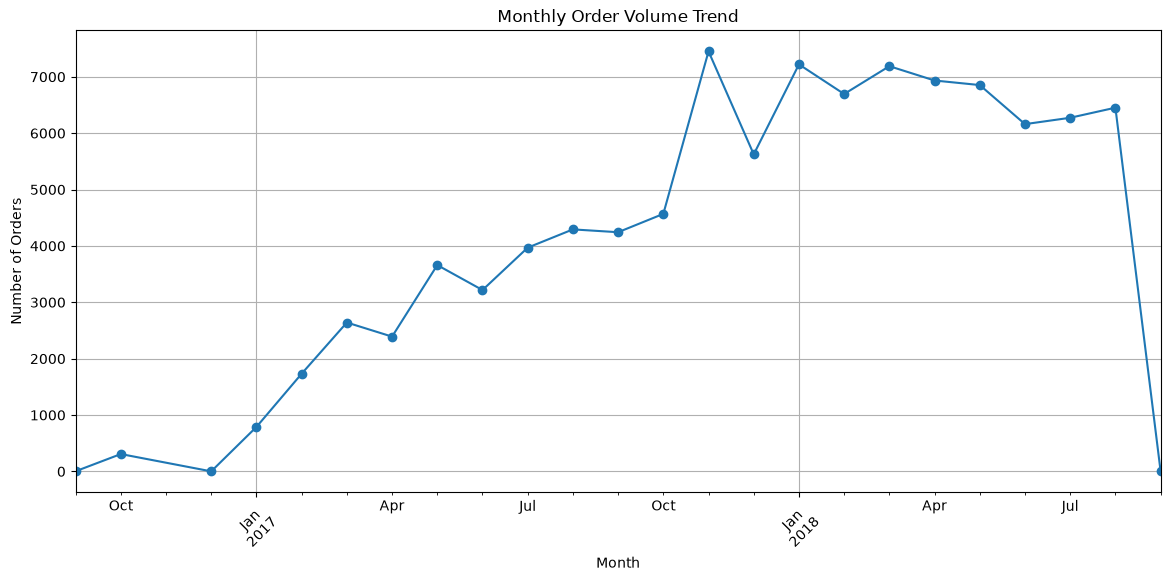

In [304]:
plt.figure(figsize=(14,6))

monthly_orders.plot(
    kind='line',
    marker='o'
)

plt.title('Monthly Order Volume Trend')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

## Monthly Average Order Value Trend

In [306]:
monthly_aov = (
    df_master.groupby(
        df_master['order_purchase_timestamp'].dt.to_period('M')
    )['price'].sum()
    /
    df_master.groupby(
        df_master['order_purchase_timestamp'].dt.to_period('M')
    )['order_id'].nunique()
)

print(monthly_aov.round(2))

order_purchase_timestamp
2016-09     89.12
2016-10    160.74
2016-12     10.90
2017-01    152.49
2017-02    142.70
2017-03    141.74
2017-04    150.53
2017-05    138.27
2017-06    134.61
2017-07    125.48
2017-08    133.70
2017-09    147.16
2017-10    145.41
2017-11    135.59
2017-12    132.27
2018-01    131.58
2018-02    126.11
2018-03    136.79
2018-04    143.73
2018-05    145.41
2018-06    140.44
2018-07    142.76
2018-08    132.47
2018-09    145.00
Freq: M, dtype: float64


### Monthly AOV Trend Chart

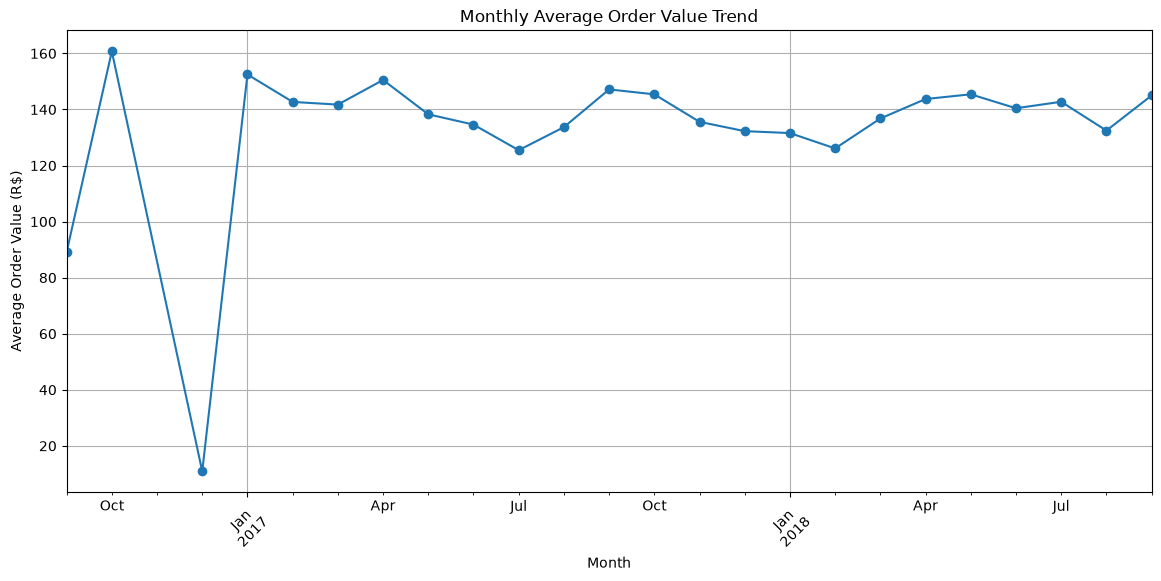

In [308]:
plt.figure(figsize=(14,6))

monthly_aov.plot(
    kind='line',
    marker='o'
)

plt.title('Monthly Average Order Value Trend')
plt.xlabel('Month')
plt.ylabel('Average Order Value (R$)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### Freight Cost Analysis

In [309]:
total_freight = df_master['freight_value'].sum()

average_freight = df_master['freight_value'].mean()

print("Total Freight Revenue: R$", round(total_freight, 2))
print("Average Freight per Item: R$", round(average_freight, 2))

Total Freight Revenue: R$ 2251909.54
Average Freight per Item: R$ 19.99


## Freight as Percentage of Product Revenue

In [310]:
freight_percentage = (
    total_freight / total_revenue
) * 100

print(
    "Freight Revenue Percentage:",
    round(freight_percentage, 2), "%"
)

Freight Revenue Percentage: 16.57 %


### Product Revenue vs Freight Revenue Chart

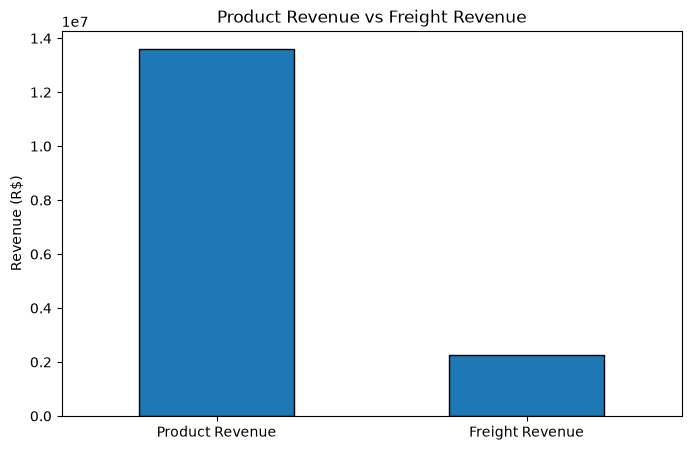

In [311]:
revenue_comparison = pd.Series({
    'Product Revenue': total_revenue,
    'Freight Revenue': total_freight
})

plt.figure(figsize=(8,5))

revenue_comparison.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Product Revenue vs Freight Revenue')
plt.ylabel('Revenue (R$)')
plt.xticks(rotation=0)
plt.show()

### Average Delivery Time

In [312]:
avg_delivery_time = df_master['delivery_days'].mean()

print("Average Delivery Time:", round(avg_delivery_time, 2), "days")

Average Delivery Time: 12.01 days


### Delivery Time Distribution

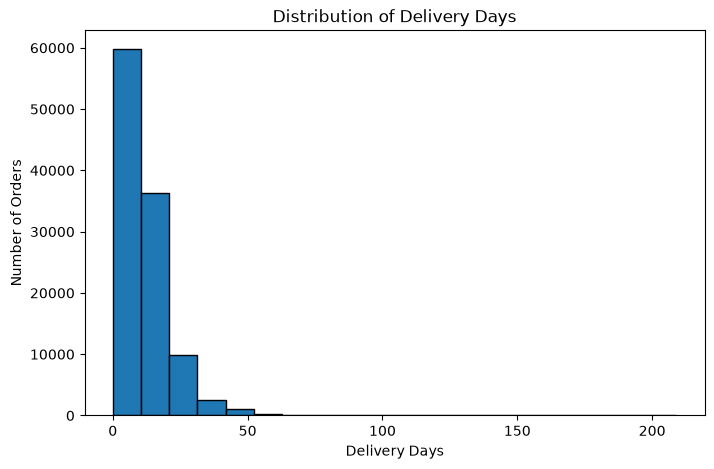

In [313]:
plt.figure(figsize=(8,5))

plt.hist(
    df_master['delivery_days'].dropna(),
    bins=20,
    edgecolor='black'
)

plt.title('Distribution of Delivery Days')
plt.xlabel('Delivery Days')
plt.ylabel('Number of Orders')
plt.show()

### Average Delivery Time by Customer State

In [314]:
state_delivery = df_master.groupby('customer_state')['delivery_days'].mean().sort_values()

print(state_delivery.round(2))

customer_state
SP     8.26
PR    11.48
MG    11.52
DF    12.50
SC    14.52
RJ    14.69
RS    14.71
GO    14.95
MS    15.11
ES    15.19
TO    17.00
MT    17.51
PE    17.79
BA    18.77
RN    18.87
PI    18.93
RO    19.28
PB    20.12
AC    20.33
CE    20.54
SE    20.98
MA    21.20
PA    23.30
AL    23.99
AM    25.96
AP    27.75
RR    27.83
Name: delivery_days, dtype: float64


## State-wise Delivery Time Chart

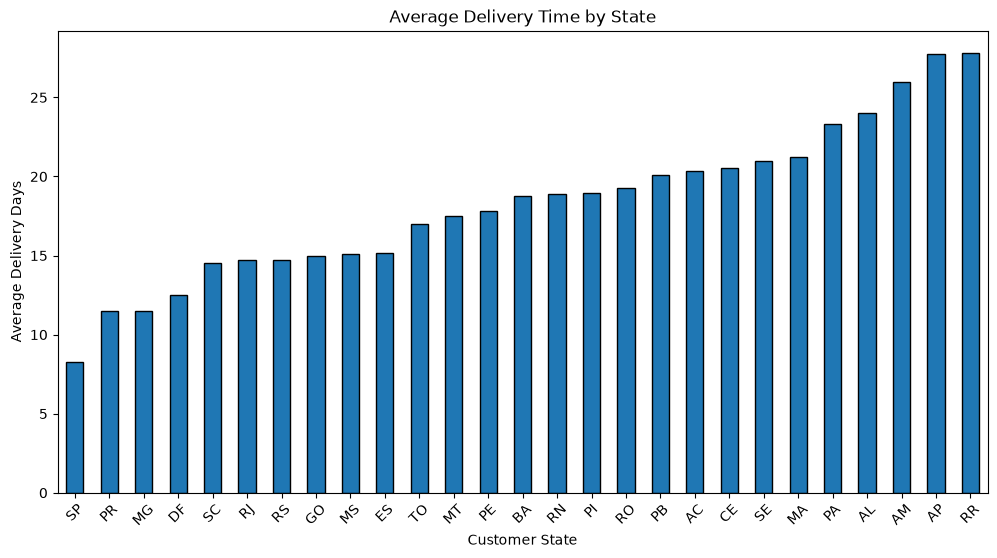

In [315]:
plt.figure(figsize=(12,6))

state_delivery.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Average Delivery Time by State')
plt.xlabel('Customer State')
plt.ylabel('Average Delivery Days')
plt.xticks(rotation=45)
plt.show()

## Cancellation Rate

In [316]:
total_orders = df_orders['order_id'].nunique()

cancelled_orders = df_orders[
    df_orders['order_status'] == 'canceled'
]['order_id'].nunique()

cancellation_rate = (
    cancelled_orders / total_orders
) * 100

print("Total Orders:", total_orders)
print("Cancelled Orders:", cancelled_orders)
print("Cancellation Rate:", round(cancellation_rate, 2), "%")

Total Orders: 99441
Cancelled Orders: 625
Cancellation Rate: 0.63 %


### Order Status Distribution Chart

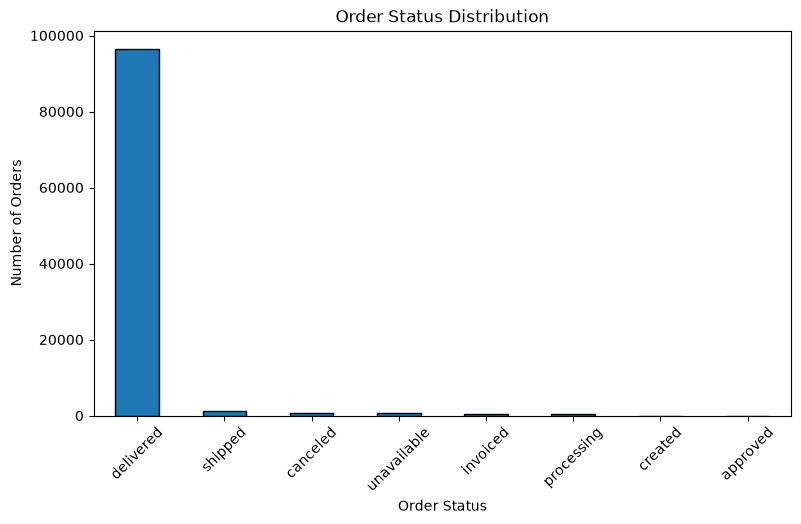

In [317]:
order_status_counts = df_orders['order_status'].value_counts()

plt.figure(figsize=(9,5))

order_status_counts.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.show()

### Order Fulfillment Rate

In [318]:
delivered_orders = df_orders[
    df_orders['order_status'] == 'delivered'
]['order_id'].nunique()

fulfillment_rate = (
    delivered_orders / total_orders
) * 100

print("Delivered Orders:", delivered_orders)
print("Order Fulfillment Rate:", round(fulfillment_rate, 2), "%")

Delivered Orders: 96478
Order Fulfillment Rate: 97.02 %


### Revenue by Payment Type

In [319]:
payment_revenue = df_payments.groupby('payment_type')[
    'payment_value'
].sum().sort_values(ascending=False)

print(payment_revenue.round(2))

payment_type
credit_card    12542084.19
boleto          2869361.27
voucher          379436.87
debit_card       217989.79
not_defined           0.00
Name: payment_value, dtype: float64


### Payment Type Revenue Chart

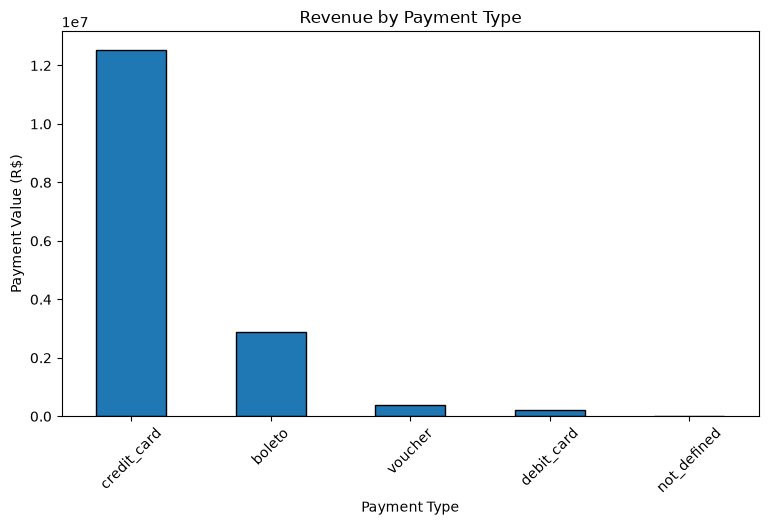

In [320]:
plt.figure(figsize=(9,5))

payment_revenue.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Revenue by Payment Type')
plt.xlabel('Payment Type')
plt.ylabel('Payment Value (R$)')
plt.xticks(rotation=45)
plt.show()

## Payment Method Usage Percentage

In [321]:
payment_usage = df_payments['payment_type'].value_counts()

payment_percentage = (
    payment_usage / payment_usage.sum()
) * 100

print(payment_percentage.round(2))

payment_type
credit_card    73.92
boleto         19.04
voucher         5.56
debit_card      1.47
not_defined     0.00
Name: count, dtype: float64


### Payment Usage Pie Chart

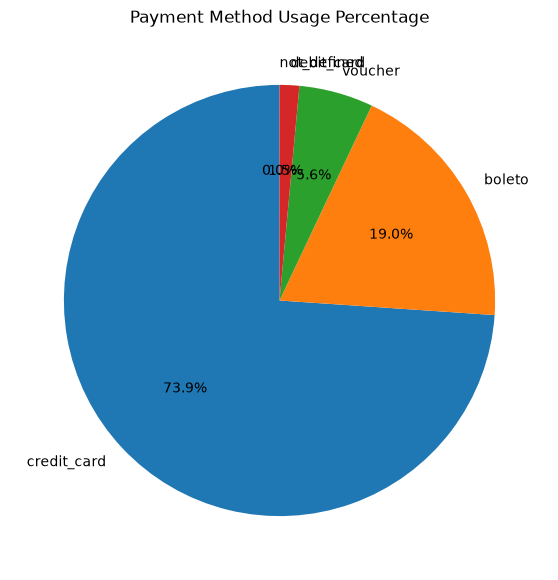

In [322]:
plt.figure(figsize=(7,7))

payment_usage.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Payment Method Usage Percentage')
plt.ylabel('')
plt.show()

### Monthly Cancellation Trend

In [323]:
cancelled_monthly = df_orders[
    df_orders['order_status'] == 'canceled'
].groupby('order-month')['order_id'].nunique()

print(cancelled_monthly)

order-month
1      37
2      90
3      59
4      33
5      53
6      34
7      69
8     111
9      37
10     54
11     37
12     11
Name: order_id, dtype: int64


### Year-wise Monthly Cancellation Trend

In [324]:
cancelled_orders = df_orders[
    df_orders['order_status'] == 'canceled'
].copy()

cancelled_orders['cancel_month'] = (
    cancelled_orders['order_purchase_timestamp'].dt.to_period('M')
)

cancelled_monthly = cancelled_orders.groupby(
    'cancel_month'
)['order_id'].nunique()

print(cancelled_monthly)

cancel_month
2016-09     2
2016-10    24
2017-01     3
2017-02    17
2017-03    33
2017-04    18
2017-05    29
2017-06    16
2017-07    28
2017-08    27
2017-09    20
2017-10    26
2017-11    37
2017-12    11
2018-01    34
2018-02    73
2018-03    26
2018-04    15
2018-05    24
2018-06    18
2018-07    41
2018-08    84
2018-09    15
2018-10     4
Freq: M, Name: order_id, dtype: int64


### Monthly Cancellation Trend Chart

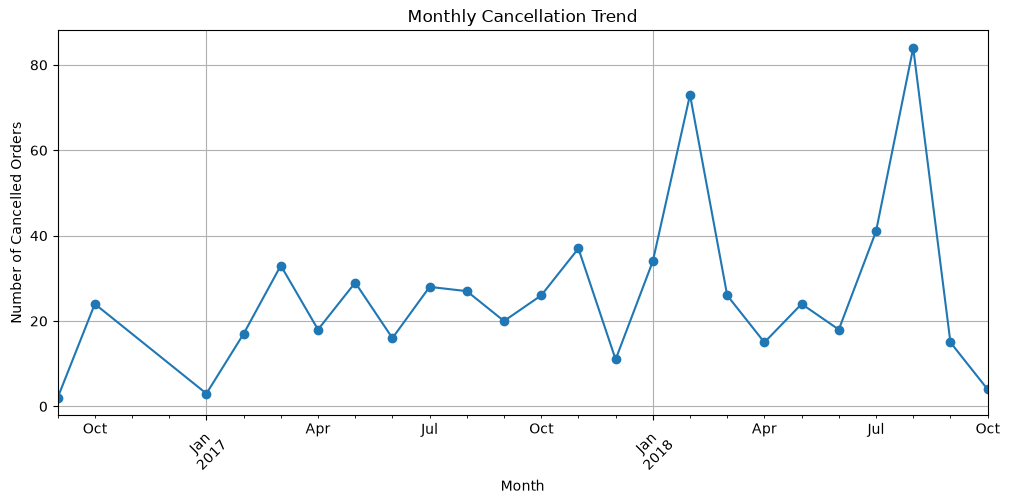

In [325]:
plt.figure(figsize=(12,5))

cancelled_monthly.plot(
    kind='line',
    marker='o',
    figsize=(12,5)
)

plt.title('Monthly Cancellation Trend')
plt.xlabel('Month')
plt.ylabel('Number of Cancelled Orders')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### Cancellation Rate by Year-Month

In [326]:
monthly_total = df_orders.groupby(
    df_orders['order_purchase_timestamp'].dt.to_period('M')
)['order_id'].nunique()

monthly_cancelled = cancelled_orders.groupby(
    'cancel_month'
)['order_id'].nunique()

monthly_cancellation_rate = (
    monthly_cancelled / monthly_total
) * 100

print(monthly_cancellation_rate.round(2))

cancel_month
2016-09     50.00
2016-10      7.41
2016-12       NaN
2017-01      0.38
2017-02      0.96
2017-03      1.23
2017-04      0.75
2017-05      0.78
2017-06      0.49
2017-07      0.70
2017-08      0.62
2017-09      0.47
2017-10      0.56
2017-11      0.49
2017-12      0.19
2018-01      0.47
2018-02      1.09
2018-03      0.36
2018-04      0.22
2018-05      0.35
2018-06      0.29
2018-07      0.65
2018-08      1.29
2018-09     93.75
2018-10    100.00
Freq: M, Name: order_id, dtype: float64


## Monthly Cancellation Rate Chart

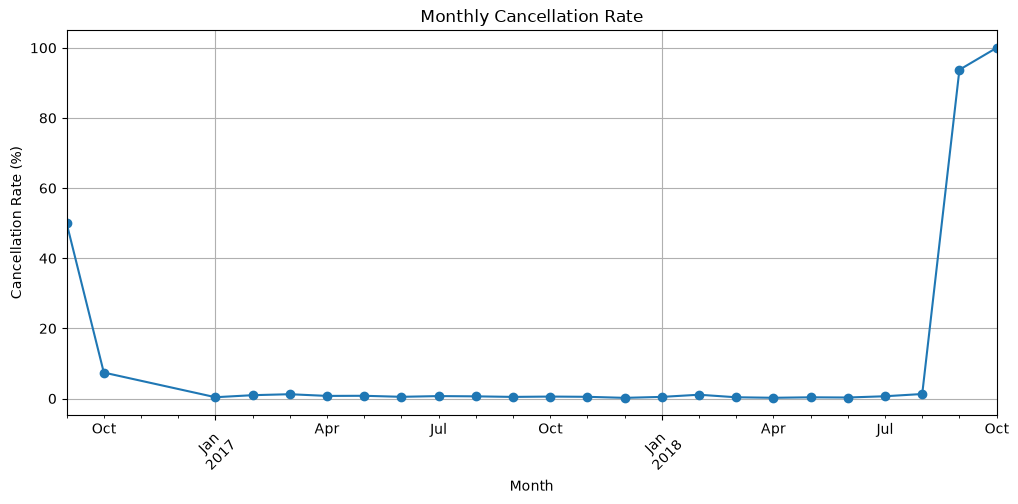

In [327]:
plt.figure(figsize=(12,5))

monthly_cancellation_rate.dropna().plot(
    kind='line',
    marker='o'
)

plt.title('Monthly Cancellation Rate')
plt.xlabel('Month')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

## Top 10 Products by Revenue

In [328]:
top_products = df_master.groupby('product_id').agg(
    total_revenue=('price', 'sum'),
    total_quantity=('order_item_id', 'count')
).sort_values(
    by='total_revenue',
    ascending=False
).head(10)

print(top_products.round(2))

                                  total_revenue  total_quantity
product_id                                                     
bb50f2e236e5eea0100680137654686c       63885.00             195
6cdd53843498f92890544667809f1595       54730.20             156
d6160fb7873f184099d9bc95e30376af       48899.34              35
d1c427060a0f73f6b889a5c7c61f2ac4       47214.51             343
99a4788cb24856965c36a24e339b6058       43025.56             488
3dd2a17168ec895c781a9191c1e95ad7       41082.60             274
25c38557cf793876c5abdd5931f922db       38907.32              38
5f504b3a1c75b73d6151be81eb05bdc9       37733.90              63
53b36df67ebb7c41585e8d54d6772e08       37683.42             323
aca2eb7d00ea1a7b8ebd4e68314663af       37608.90             527


## Top 10 Products by Revenue – Chart

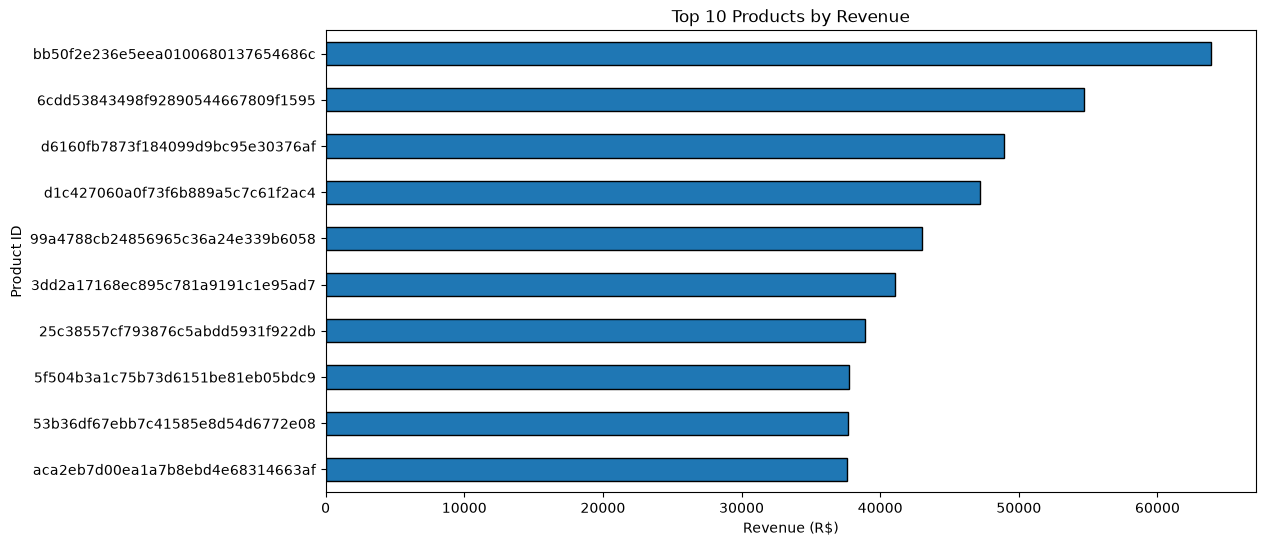

In [329]:
plt.figure(figsize=(12,6))

top_products['total_revenue'].sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (R$)')
plt.ylabel('Product ID')
plt.show()

## Top 10 Best-Selling Products by Quantity

In [330]:
top_quantity_products = df_master.groupby('product_id').agg(
    total_quantity=('order_item_id', 'count'),
    total_revenue=('price', 'sum')
).sort_values(
    by='total_quantity',
    ascending=False
).head(10)

print(top_quantity_products.round(2))

                                  total_quantity  total_revenue
product_id                                                     
aca2eb7d00ea1a7b8ebd4e68314663af             527       37608.90
99a4788cb24856965c36a24e339b6058             488       43025.56
422879e10f46682990de24d770e7f83d             484       26577.22
389d119b48cf3043d311335e499d9c6b             392       21440.59
368c6c730842d78016ad823897a372db             388       21056.80
53759a2ecddad2bb87a079a1f1519f73             373       20387.20
d1c427060a0f73f6b889a5c7c61f2ac4             343       47214.51
53b36df67ebb7c41585e8d54d6772e08             323       37683.42
154e7e31ebfa092203795c972e5804a6             281        6325.19
3dd2a17168ec895c781a9191c1e95ad7             274       41082.60


## Top 10 Products by Quantity – Chart

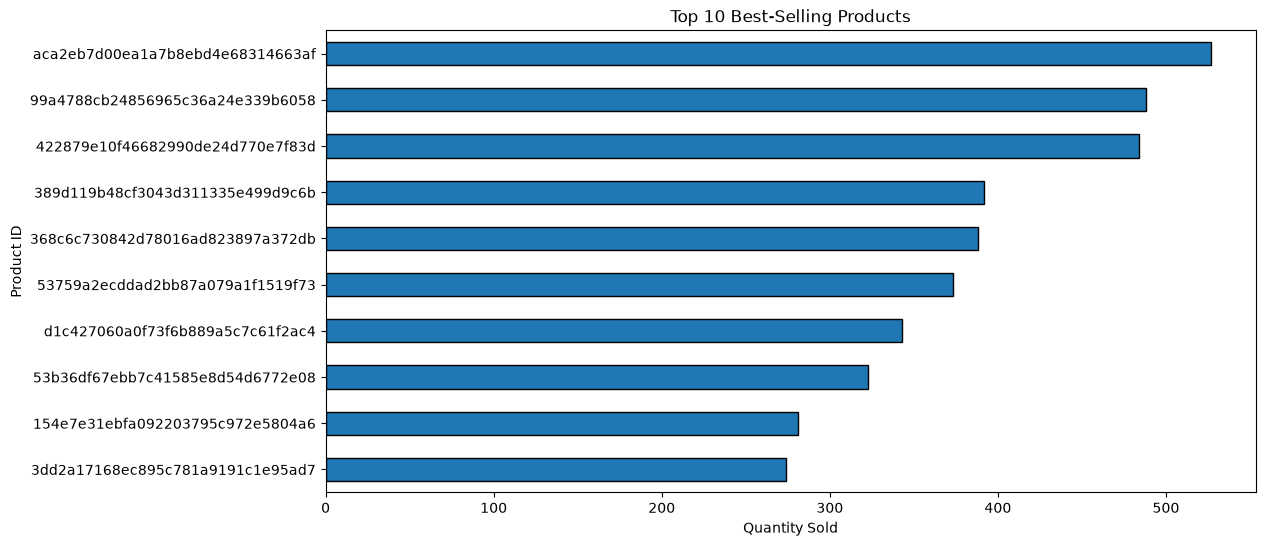

In [331]:
plt.figure(figsize=(12,6))

top_quantity_products['total_quantity'].sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Quantity Sold')
plt.ylabel('Product ID')
plt.show()

## Top 10 Product Categories by Quantity Sold

In [332]:
top_categories_quantity = df_master.groupby(
    'product_category_name_english'
)['order_item_id'].count().sort_values(
    ascending=False
).head(10)

print(top_categories_quantity)

product_category_name_english
bed_bath_table           11115
health_beauty             9670
sports_leisure            8641
furniture_decor           8334
computers_accessories     7827
housewares                6964
watches_gifts             5991
telephony                 4545
garden_tools              4347
auto                      4235
Name: order_item_id, dtype: int64


## Category-wise Quantity Chart

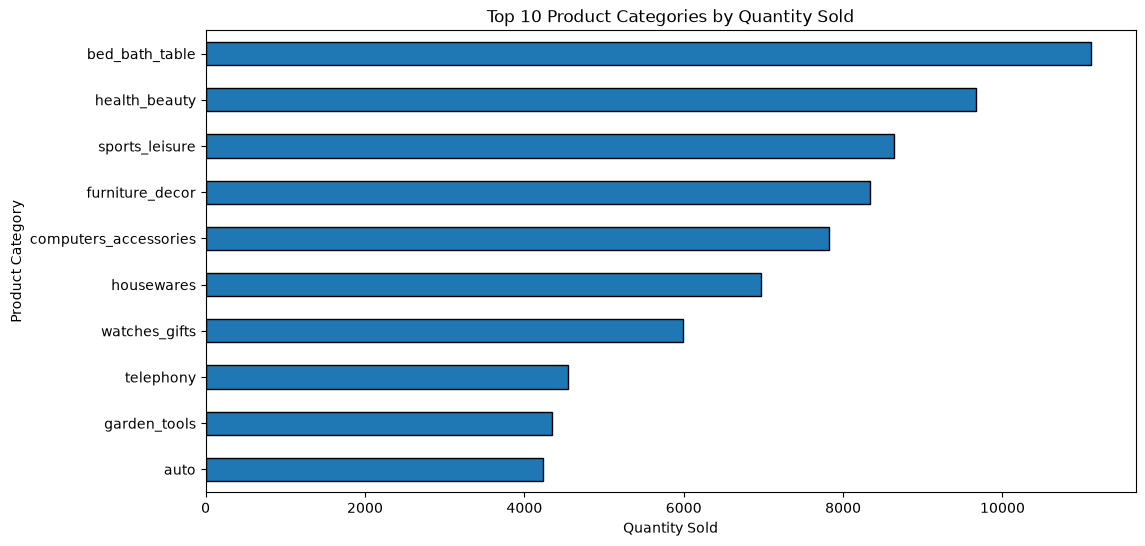

In [333]:
plt.figure(figsize=(12,6))

top_categories_quantity.sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Top 10 Product Categories by Quantity Sold')
plt.xlabel('Quantity Sold')
plt.ylabel('Product Category')
plt.show()

### Revenue Contribution by Top 10 Categories

In [334]:
category_revenue = df_master.groupby(
    'product_category_name_english'
)['price'].sum().sort_values(ascending=False)

top_10_revenue = category_revenue.head(10)

revenue_contribution = (
    top_10_revenue.sum() / total_revenue
) * 100

print("Top 10 Categories Revenue:", round(top_10_revenue.sum(), 2))
print("Total Product Revenue:", round(total_revenue, 2))
print("Revenue Contribution:", round(revenue_contribution, 2), "%")

Top 10 Categories Revenue: 8475957.56
Total Product Revenue: 13591643.7
Revenue Contribution: 62.36 %


### Top 10 Categories Revenue Contribution Chart

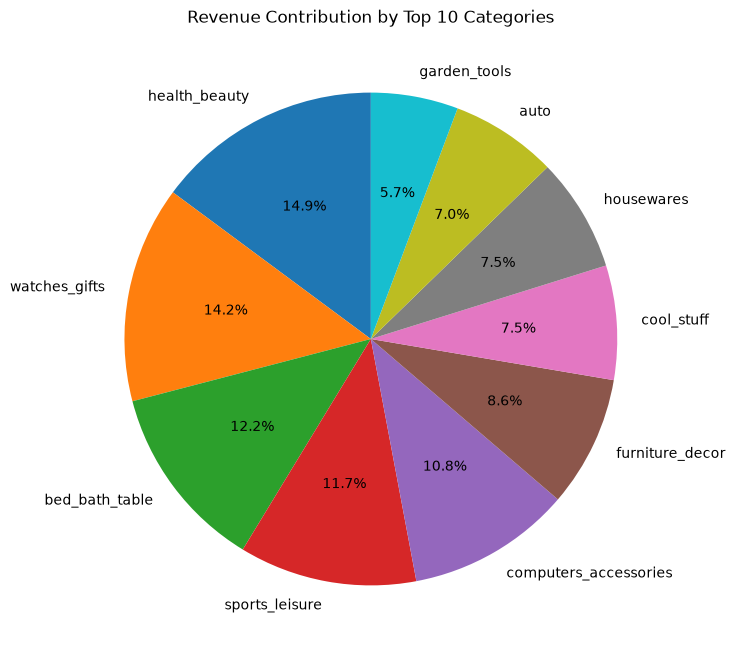

In [335]:
plt.figure(figsize=(8,8))

top_10_revenue.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Revenue Contribution by Top 10 Categories')
plt.ylabel('')
plt.show()

## Revenue Concentration – Top 5 Categories

In [336]:
top_5_revenue = category_revenue.head(5)

top_5_contribution = (
    top_5_revenue.sum() / total_revenue
) * 100

print("Top 5 Categories Revenue:", round(top_5_revenue.sum(), 2))
print("Top 5 Revenue Contribution:", round(top_5_contribution, 2), "%")

Top 5 Categories Revenue: 5400678.99
Top 5 Revenue Contribution: 39.74 %


## Top 5 Categories Chart

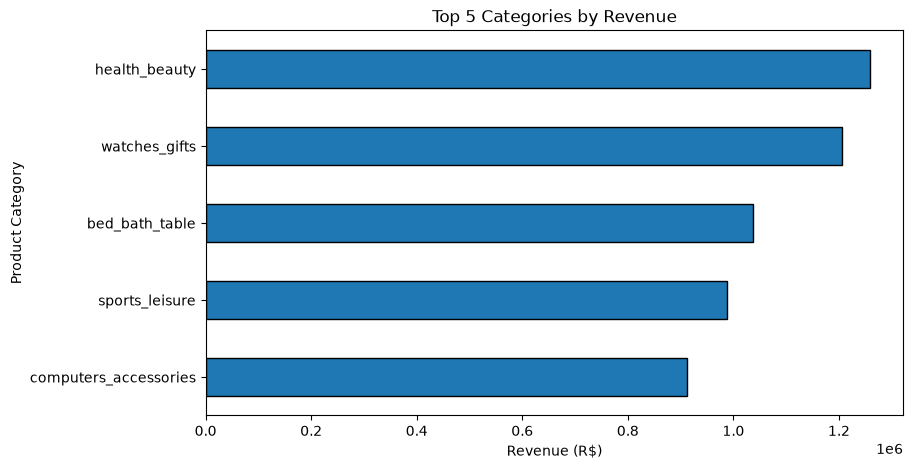

In [337]:
plt.figure(figsize=(9,5))

top_5_revenue.sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Top 5 Categories by Revenue')
plt.xlabel('Revenue (R$)')
plt.ylabel('Product Category')
plt.show()

## Correct Delivery Status

In [338]:
df_orders['delivery_status'] = np.select(
    [
        df_orders['delivery_difference'].isna(),
        df_orders['delivery_difference'] > 0,
        df_orders['delivery_difference'] < 0
    ],
    ['Unknown', 'Late', 'Early'],
    default='On Time'
)

print(df_orders['delivery_status'].value_counts())

delivery_status
Early      88649
Late        6535
Unknown     2965
On Time     1292
Name: count, dtype: int64


## Recalculate Delivery Satisfaction

In [339]:
delivery_review = df_orders[
    ['order_id', 'delivery_status']
].merge(
    review_summary,
    on='order_id',
    how='left'
)

delivery_satisfaction = delivery_review.groupby(
    'delivery_status'
)['avg_review_score'].mean()

print(delivery_satisfaction.round(2))

delivery_status
Early      4.29
Late       2.27
On Time    4.04
Unknown    1.75
Name: avg_review_score, dtype: float64


## Delivery Satisfaction Chart

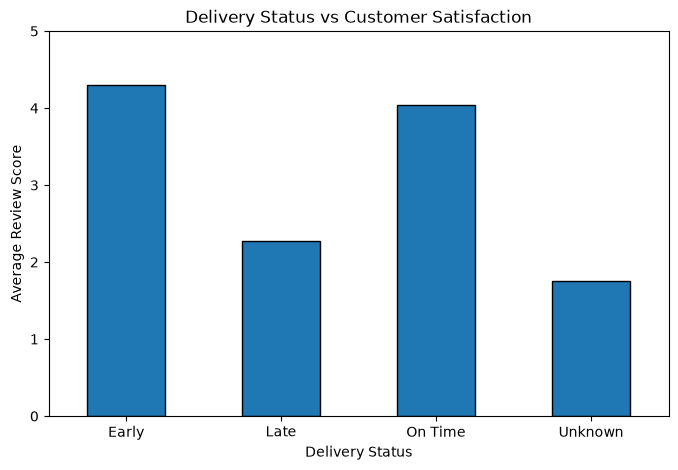

In [340]:
plt.figure(figsize=(8,5))

delivery_satisfaction.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Delivery Status vs Customer Satisfaction')
plt.xlabel('Delivery Status')
plt.ylabel('Average Review Score')
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.show()

## Seller Performance Validation

In [341]:
print("Original Sellers:", df_sellers['seller_id'].nunique())

print("Master Dataset Sellers:", df_master['seller_id'].nunique())

print("Seller Count Match:",
      df_sellers['seller_id'].nunique() == df_master['seller_id'].nunique())

Original Sellers: 3095
Master Dataset Sellers: 3095
Seller Count Match: True


## Customer Count Validation

In [342]:
print("Original Customers:",
      df_customer['customer_unique_id'].nunique())

print("Master Dataset Customers:",
      df_master['customer_unique_id'].nunique())

print("Customer Count Match:",
      df_customer['customer_unique_id'].nunique() ==
      df_master['customer_unique_id'].nunique())

Original Customers: 96096
Master Dataset Customers: 95420
Customer Count Match: False


### Missing Customers Investigation

In [343]:
missing_customer_ids = set(
    df_customer['customer_unique_id']
) - set(
    df_master['customer_unique_id']
)

print("Missing Unique Customers:",
      len(missing_customer_ids))

missing_customers = df_customer[
    df_customer['customer_unique_id'].isin(missing_customer_ids)
]

print("Missing Customer Records:",
      missing_customers.shape)

print("Missing Customers with Orders:",
      df_orders['customer_id'].isin(
          missing_customers['customer_id']
      ).sum())

Missing Unique Customers: 676
Missing Customer Records: (685, 5)
Missing Customers with Orders: 685


## Check Missing Customers' Order Items

In [344]:
missing_customer_orders = df_orders[
    df_orders['customer_id'].isin(
        missing_customers['customer_id']
    )
]

print("Missing Customers' Orders:",
      missing_customer_orders['order_id'].nunique())

print("Orders Found in Master Dataset:",
      missing_customer_orders['order_id'].isin(
          df_master['order_id']
      ).sum())

print("\nOrder Status:")
print(missing_customer_orders['order_status'].value_counts())

Missing Customers' Orders: 685
Orders Found in Master Dataset: 0

Order Status:
order_status
unavailable    569
canceled       109
created          4
invoiced         2
shipped          1
Name: count, dtype: int64


## Validate Product Count

In [345]:
print("Original Products:",
      df_products['product_id'].nunique())

print("Master Dataset Products:",
      df_master['product_id'].nunique())

print("Product Count Match:",
      df_products['product_id'].nunique() ==
      df_master['product_id'].nunique())

Original Products: 32951
Master Dataset Products: 32951
Product Count Match: True


## Master Dataset Final Validation

In [346]:
print("Master Dataset Shape:", df_master.shape)

print("Duplicate Rows:", df_master.duplicated().sum())

print("Unique Orders:", df_master['order_id'].nunique())

print("Unique Products:", df_master['product_id'].nunique())

print("Unique Sellers:", df_master['seller_id'].nunique())

print("Missing Values:", df_master.isnull().sum().sum())

Master Dataset Shape: (112650, 47)
Duplicate Rows: 0
Unique Orders: 98666
Unique Products: 32951
Unique Sellers: 3095
Missing Values: 19396


## Missing Values by Column

In [348]:
missing_summary = df_master.isnull().sum()

missing_summary = missing_summary[
    missing_summary > 0
].sort_values(ascending=False)

print(missing_summary)

order_delivered_customer_date    2454
delivery_difference              2454
delivery_days                    2454
product_description_lenght       1603
product_photos_qty               1603
product_category_name            1603
product_name_lenght              1603
product_category_name_english    1603
order_delivered_carrier_date     1194
avg_review_score                  942
review_count                      942
avg_latitude                      253
avg_longitude                     253
geolocation_zip_code_prefix       253
product_weight_g                   18
product_volume_cm3                 18
product_length_cm                  18
product_width_cm                   18
product_height_cm                  18
product_width_cleaned              17
product_height_cleaned             17
product_length_cleaned             17
product_weight_cleaned             17
order_approved_at                  15
total_payment_value                 3
max_installments                    3
payment_coun

### Final KPI Dashboard Summary

In [349]:
print("========== OLIST BUSINESS KPI SUMMARY ==========")

print("Total Revenue: R$", round(total_revenue, 2))

print("Total Orders:", df_master['order_id'].nunique())

print("Total Customers:", df_master['customer_unique_id'].nunique())

print("Total Products Sold:", len(df_master))

print("Average Order Value: R$", round(
    total_revenue / df_master['order_id'].nunique(), 2
))

print("Total Freight Revenue: R$", round(total_freight, 2))

print("Average Delivery Time:", round(avg_delivery_time, 2), "days")

print("Cancellation Rate:", round(cancellation_rate, 2), "%")

print("Order Fulfillment Rate:", round(fulfillment_rate, 2), "%")

print("Repeat Customer Rate:", round(
    (2913 / 95420) * 100, 2
), "%")

print("================================================")

========== OLIST BUSINESS KPI SUMMARY ==========
Total Revenue: R$ 13591643.7
Total Orders: 98666
Total Customers: 95420
Total Products Sold: 112650
Average Order Value: R$ 137.75
Total Freight Revenue: R$ 2251909.54
Average Delivery Time: 12.01 days
Cancellation Rate: 0.63 %
Order Fulfillment Rate: 97.02 %
Repeat Customer Rate: 3.05 %



## Business Recommendations
#### 1. Customer Retention: Repeat customer rate sirf 3.05% hai. Loyalty programs, personalized offers aur repeat-purchase campaigns introduce karne chahiye.
#### 2. Delivery Improvement: Late deliveries ka average review score 2.27 hai, jabki early deliveries ka 4.29. Delivery delays reduce karne par focus karna chahiye.
#### 3. Category Strategy: Health & Beauty revenue mein top hai, jabki Bed Bath & Table orders aur quantity mein top hai. Dono categories ke liye separate sales strategies useful hongi.
#### 4. Payment Strategy: Credit card payment value sabse zyada hai. Payment experience ko smooth aur secure rakhna chahiye.


## Final Conclusion

This project involved an end-to-end analysis of the Brazilian Olist E-Commerce dataset using Python, Pandas, NumPy, and Matplotlib.

The analysis covered data cleaning, data integration, exploratory data analysis, business KPI calculation, and visualization.

### Key findings
 
-Total product revenue was R$13.59 million

-A total of 98,666 unique orders were analyzed.
- Average Order Value (AOV) was R$137.75.
- Credit cards were the most commonly used payment method.
- The repeat customer rate was approximately 3.05%.
- Late deliveries were associated with significantly lower customer review scores.
- Health & Beauty generated the highest category revenue.

The analysis identified opportunities to improve customer retention, delivery performance, and category-level business strategies.

Overall, this project helped develop practical skills in data cleaning, data analysis, visualization, and deriving business insights from real-world e-commerce data.